# Entrega final: Pensamiento Crítico II y Estadística Bayesiana

**Universidad Externado de Colombia · Facultad de Matemáticas · Pregrado en Ciencia de Datos**

**Proyecto:** Variación mensual de las ventas de muebles y artículos del hogar: una referencia para el inventario

**Integrantes:** Juan Esteban Jiménez Aristizábal, David Quijano, Juan Esteban Zambrano, Juan Angel Triana Olarte

**Datos:** FRED — Federal Reserve Bank of St. Louis (https://fred.stlouisfed.org), series del U.S. Census Bureau y del Bureau of Economic Analysis.

## Sección 0. Configuración

Datos en carpeta `data` (local) o en GitHub: [repositorio del equipo](https://github.com/Agarslok/Variaci-n-mensual-de-las-ventas-de-muebles-US-con-estadistica-bayesiana).

Verificación rápida: `MODO_RAPIDO=1`. Entrega final: `MODO_RAPIDO=0` (30 000 quemado + 40 000 iteraciones por cadena).

In [ ]:
from pathlib import Path
import os
import shutil
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import optimize, stats
from scipy.special import gammaln

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Datos: carpeta data/ local, o descarga desde el repo del equipo (rama main, carpeta data).
GITHUB_DATA = os.environ.get(
    "GITHUB_DATA",
    "https://raw.githubusercontent.com/Agarslok/Variaci-n-mensual-de-las-ventas-de-muebles-US-con-estadistica-bayesiana/main/data",
).strip()
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"

SEMILLA = 2026
N_SIM = 4000
ARCHIVOS = ["base_hogar_modelo.csv", "diccionario_variables.csv"]

Y = "crec_muebles_hogar"
X = [
    "crec_electro",
    "crec_sin_tienda",
    "crec_construccion",
    "crec_tiendas_generales",
    "crec_gasolineras",
    "crec_ingreso_disponible",
    "razon_inv_ventas_rezago1",
    "crec_muebles_hogar_rezago1",
]
CUANTI = [Y] + X
rng = np.random.default_rng(SEMILLA)


import urllib.request


def _buscar_data():
    for base in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        cand = base / "data"
        if (cand / ARCHIVOS[0]).exists():
            return cand
    return None


def _descargar_desde_github(carpeta: Path, base_url: str) -> None:
    if not base_url:
        raise FileNotFoundError("No hay carpeta data local y GITHUB_DATA está vacío.")
    carpeta.mkdir(parents=True, exist_ok=True)
    base = base_url.rstrip("/")
    for nombre in ARCHIVOS:
        dest = carpeta / nombre
        if dest.exists():
            continue
        urllib.request.urlretrieve(f"{base}/{nombre}", dest)
        print(f"Descargado: {nombre}")


CARPETA_DATOS = _buscar_data()
if CARPETA_DATOS is None:
    CARPETA_DATOS = Path.cwd() / "data"
    _descargar_desde_github(CARPETA_DATOS, GITHUB_DATA)

faltan = [a for a in ARCHIVOS if not (CARPETA_DATOS / a).exists()]
if faltan:
    raise FileNotFoundError(f"Faltan {faltan}. Coloque los CSV en data/ o configure GITHUB_DATA.")

CARPETA_SALIDAS = Path("figuras")
CARPETA_TABLAS = Path("tablas")
CARPETA_SALIDAS.mkdir(exist_ok=True)
CARPETA_TABLAS.mkdir(exist_ok=True)
CARPETA = CARPETA_DATOS.parent
if MODO_RAPIDO:
    print("MODO_RAPIDO activo (MCMC reducido).")


def titulo(texto):
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(CARPETA_SALIDAS / nombre, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"   [figura guardada] {nombre}")


def guardar_tabla(tabla, nombre, indice=True):
    dest = CARPETA_TABLAS / nombre
    tabla.to_csv(dest, index=indice, encoding="utf-8-sig")
    print(f"   [tabla guardada] {nombre}")


Descargado: base_hogar_modelo.csv
Descargado: diccionario_variables.csv


# Parte A. Planteamiento del problema, pregunta, justificación y objetivos
(Numerales 1 a 4 del PDF. Se califican en Pensamiento Crítico y en Estadística Bayesiana.)

## 1. Planteamiento del problema
Una comercializadora de artículos para el hogar debe decidir periódicamente cuánto inventario mantener y cuánto pedir, para ello necesita anticipar cómo va a cambiar la demanda. Equivocarse es costoso, si se pide de menos, los productos se agotan, se pierden ventas y clientes; si se pide de más, la mercancía queda detenida en bodega, ocupando espacio y dinero. Normalmente esa anticipación se resume en un único número y la demanda real casi nunca coincide exactamente con él. Lo que determina el costo de decidir mal es qué tan grande puede ser esa diferencia, pero quien compra rara vez cuenta con una estimación de ella. Sin saber cuánto puede desviarse la demanda de lo esperado, no hay un criterio para definir la cantidad de inventario de reserva mantener ni para saber si un pedido es razonable.

Antes de definir cuánto pedir en una empresa o de un producto concreto, hay que entender cómo se mueve la demanda del mercado en el que opera la comercializadora y qué tanto puede variar de un mes a otro. Para ello usamos las ventas minoristas mensuales de las tiendas de muebles y artículos para el hogar de todo Estados Unidos entre marzo de 1992 y julio de 2026, estimadas por el Census Bureau y publicadas en FRED. Se trata de datos agregados del sector y no de una empresa en particular, por lo que los resultados deben entenderse como una referencia de mercado que una comercializadora puede tomar como punto de partida. Elegimos esta fuente porque es pública, verificable y lo bastante extensa para estudiar la variabilidad del sector en distintas épocas.

La demanda de este sector probablemente no se mueve de forma aislada. Desde la teoría económica se espera que acompañe el ciclo de consumo de los hogares: su ingreso disponible, la actividad de categorías cercanas (electrónica y electrodomésticos, materiales de construcción, tiendas de mercancía general, ventas sin tienda) y el nivel de inventarios del comercio. Tratamos esta idea como una hipótesis de trabajo y no como un hecho establecido: la literatura sobre el sector sugiere que el ingreso se relaciona con las ventas de muebles, pero también que explica solo una parte pequeña de su variación. Por eso no es claro cuáles de estos factores acompañan realmente los cambios de las ventas ni con qué fuerza, y aclararlo es parte de lo que este proyecto busca.

Los datos muestran además que el sector no ha sido estable. En marzo y abril de 2020, coincidiendo con el inicio de la pandemia de COVID-19, las ventas mensuales cayeron cerca de 22% y 51%, en mayo y junio subieron cerca de 81% y 39%, cuando en un mes normal la variación típica es de menos de 2%. Después de ese episodio la variabilidad se mantuvo más alta, la variación típica pasó de 1.5 antes de la pandemia a más de 3 desde mediados de 2020. Este comportamiento no es exclusivo del sector, pues Lenza y Primiceri (2022) describen variaciones sin precedentes en muchas series macroeconómicas de Estados Unidos durante la pandemia. Esto significa que la variabilidad observada en el pasado no es una referencia fija y puede subestimar cuánto puede cambiar la demanda.

Dentro de la empresa, cada área mira el problema desde un interés distinto y legítimo. Compras e inventario buscan evitar tanto el desabastecimiento como el exceso. El área comercial busca cumplir metas de venta, lo que la lleva a favorecer pedidos más grandes. Finanzas cuida el dinero que queda inmovilizado en bodega. Todas estas áreas toman sus decisiones con información, como su experiencia, el historial de ventas y los pronósticos internos. Sin embargo, esa información rara vez incluye una medida explícita de cuánto puede variar la demanda del mercado, de modo que cada área puede interpretar el mismo pronóstico de forma distinta y defender un nivel de inventario diferente. Una referencia común y cuantificada sobre esa variación no reemplazaría el criterio de los gerentes, pero sí les daría una base compartida para discutir sus decisiones.

La literatura también muestra un vacío en este punto. Van Steenbergen y Mes (2020) señalan que qué tan confiable es una predicción de demanda ha sido poco estudiado, a pesar de que es justo lo que necesita quien maneja un inventario. Además, Lenza y Primiceri (2022) muestran que descartar los meses extremos de 2020 puede ser aceptable para estimar relaciones, pero subestima la incertidumbre cuando se quiere anticipar lo que viene. De ahí surge el problema, no existe una referencia clara, respaldada en datos, sobre cuánto pueden subir o bajar las ventas del sector de un mes a otro y con qué grado de certeza, que las distintas áreas de una empresa puedan usar como base común para decidir su inventario.


## 2. Pregunta de investigación

Como la empresa necesita saber qué tanto puede variar la demanda. La pregunta que guía el proyecto es la siguiente:

**¿Cuánto pueden subir o bajar las ventas minoristas de muebles y artículos para el hogar en Estados Unidos de un mes a otro, y con qué certeza puede estimarse ese cambio para apoyar el inventario de una comercializadora?**

## 3. Justificación

Este proyecto es útil porque las decisiones de inventario se siguen tomando con una cifra puntual, cuando lo que más pesa en el costo es qué tan lejos puede quedar la demanda real de esa cifra. Un rango creíble de variación mensual permite a un encargado de compras fijar un inventario de seguridad con un criterio para darle a compras, ventas y finanzas un número común sobre el cual discutir.

También es relevante porque ayuda a entender un sector que se vio muy afectado por eventos inesperados. Saber cuánta variación es normal, cuánta se ha visto en condiciones extremas y qué tanto cambió la volatilidad después de 2020 permite a una empresa prepararse mejor, en lugar de reaccionar cuando ya es tarde. Desde lo académico, el trabajo contribuye al vacío señalado en la literatura, porque pone la incertidumbre de la estimación en el centro del análisis y no como un detalle secundario.

Usamos un enfoque bayesiano porque expresa lo que sabemos y lo que no sabemos en forma de probabilidades. Así podemos decir qué tan probable es que las ventas suban o bajen cierta cantidad, o qué tan probable es que un factor realmente acompañe los cambios del sector, en lugar de limitarnos a decir si algo es significativo o no. Además, permite incorporar información previa razonable y conservar los meses extremos de 2020 en el análisis, tratándolos como episodios excepcionales y no eliminándolos, lo que haría parecer al sector más estable de lo que es.

Por último, el proyecto es honesto sobre lo que puede ofrecer. Los cambios mensuales de este sector son difíciles de anticipar,los factores considerados acompañan esos cambios, pero explican solo una parte pequeña de ellos. Por eso el aporte principal no es acertar una cifra exacta sino entregar un rango bien calibrado, que es justamente lo que le falta hoy a quien decide un inventario.


## 4. Objetivos

### 4.1 Objetivo general
Estimar cuánto pueden subir o bajar mensualmente las ventas minoristas de muebles y artículos para el hogar en Estados Unidos, y cuantificar la incertidumbre de esa estimación, para ofrecer una referencia que apoye las decisiones de inventario de una empresa del sector.

### 4.2 Objetivos específicos

1. Describir el comportamiento histórico de las ventas del sector, identificando sus variaciones normales, su volatilidad y los episodios extremos.
2. Identificar qué categorías del comercio y qué condiciones de los hogares se asocian con los cambios en las ventas del sector y con qué fuerza.
3. Cuantificar la incertidumbre de las estimaciones, teniendo en cuenta que la variabilidad del sector ha cambiado en el tiempo y que los episodios extremos de 2020 no deben distorsionar el resultado.
4. Evaluar qué tan bien responde la estimación ante datos que no se usaron para construirla (los últimos 24 meses) y compararla con alternativas más simples.
5. Construir un rango de referencia para las ventas esperadas del sector el mes siguiente y explicar cómo una comercializadora puede usarlo como punto de partida para su decisión de inventario y cuáles son sus límites
### 4.3 Alcance y limitaciones

El proyecto trabaja con series agregadas de Estados Unidos, ajustadas estacionalmente, por lo que sus conclusiones no se trasladan directamente a una empresa en particular ni a otro país. Los valores más recientes de las series del Census son estimaciones adelantadas que luego se revisan y por eso dejamos por fuera agosto de 2026. Las variables explicativas son del mismo mes que la respuesta, así que el modelo mide asociación y no causalidad. Tampoco contamos con datos de precios ni de la competencia.

# Parte B. Análisis exploratorio de datos (EDA)
(Numeral 5 del PDF. Se califica en Estadística Bayesiana.)

Todo el análisis de esta parte usa solo los 389 meses de entrenamiento. La base de prueba se separa en 5.3 y no se explora.

### 5.1 Carga y validación de la base

Antes de analizar nada revisamos que la base esté bien armada: sin vacíos ni duplicados, con meses consecutivos y con las transformaciones bien calculadas. El crecimiento mensual es 100 por la diferencia del logaritmo de la serie en niveles, es decir, aproximadamente el cambio porcentual de un mes al siguiente.

In [ ]:
titulo("5.1 Carga y validación")

df = pd.read_csv(CARPETA_DATOS / "base_hogar_modelo.csv", parse_dates=["fecha"])
df = df.sort_values("fecha").reset_index(drop=True)

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print(f"Periodo: {df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}")
print(f"Valores nulos: {int(df.isna().sum().sum())}")
print(f"Filas duplicadas: {int(df.duplicated().sum())} | Fechas duplicadas: {int(df['fecha'].duplicated().sum())}")

meses = df["fecha"].dt.year * 12 + df["fecha"].dt.month
print(f"Huecos en la serie mensual: {int((meses.diff().dropna() != 1).sum())}")

rezago_ok = np.allclose(df[Y].shift(1).iloc[1:], df["crec_muebles_hogar_rezago1"].iloc[1:])
print(f"El rezago de Y coincide con Y desplazada un mes: {rezago_ok}")

recalculo = 100 * np.log(df["nivel_muebles_hogar"]).diff()
print(f"Máxima diferencia con 100*diff(log(nivel)): {(recalculo - df[Y]).iloc[1:].abs().max():.4f}")


5.1 Carga y validación
Filas: 413 | Columnas: 19
Periodo: 1992-03 a 2026-07
Valores nulos: 0
Filas duplicadas: 0 | Fechas duplicadas: 0
Huecos en la serie mensual: 0
El rezago de Y coincide con Y desplazada un mes: True
Máxima diferencia con 100*diff(log(nivel)): 0.0000


### 5.2 Diccionario de variables

Los nombres de las columnas son códigos que armamos a partir de los códigos de FRED. Esta tabla dice qué es cada una, de qué serie viene y qué transformación tiene.

In [ ]:
titulo("5.2 Diccionario de variables")

dicc = pd.read_csv(CARPETA_DATOS / "diccionario_variables.csv")
pd.set_option("display.max_colwidth", 80)
print(dicc.to_string(index=False))
guardar_tabla(dicc, "tabla_diccionario.csv", indice=False)


5.2 Diccionario de variables
                   columna codigo_FRED        rol                     transformacion                                                                    descripcion
             muebles_hogar      RSFHFS          Y      nivel (millones USD, desest.)                               Ventas minoristas: muebles y artículos del hogar
                   electro       RSEAS          X      nivel (millones USD, desest.)                             Ventas minoristas: electrónica y electrodomésticos
                sin_tienda       RSNSR          X      nivel (millones USD, desest.)                        Ventas minoristas: minoristas sin tienda (canal online)
              construccion    RSBMGESD          X      nivel (millones USD, desest.)                         Ventas minoristas: materiales de construcción y jardín
         tiendas_generales       RSGMS          X      nivel (millones USD, desest.)                                Ventas minoristas: tiendas de merc

### 5.3 Partición entrenamiento y prueba

La partición es por tiempo y no aleatoria, porque en una serie de tiempo no tiene sentido entrenar con el futuro. Los últimos 24 meses quedan reservados para validar el modelo en la entrega final.

In [ ]:
titulo("5.3 Partición entrenamiento y prueba")

entren = df[df["conjunto"] == "entrenamiento"].copy().reset_index(drop=True)
prueba = df[df["conjunto"] == "prueba"].copy().reset_index(drop=True)   # no se explora aquí

print(f"Entrenamiento: {len(entren)} meses ({entren['fecha'].min():%Y-%m} a {entren['fecha'].max():%Y-%m})")
print(f"Prueba (reservada): {len(prueba)} meses ({prueba['fecha'].min():%Y-%m} a {prueba['fecha'].max():%Y-%m})")


5.3 Partición entrenamiento y prueba
Entrenamiento: 389 meses (1992-03 a 2024-07)
Prueba (reservada): 24 meses (2024-08 a 2026-07)


### 5.4 Preparación: meses de COVID y submuestra de meses normales

La base trae una variable `covid_2020` que vale 1 entre marzo y junio de 2020. Con ella armamos dos versiones de los datos: la completa, que es la que usará el modelo principal, y una de meses normales, que sirve para ver cómo se comportan las variables cuando no hay episodios extremos. En la segunda quitamos también julio de 2020, porque la variable de rezago de ese mes es el valor extremo de junio y contaminaría los resultados. La submuestra de meses normales no es un modelo alternativo, es solo una forma de mirar los datos.

Para el análisis de la volatilidad también marcamos dos regímenes: antes de marzo de 2020 y desde julio de 2020.

In [ ]:
titulo("5.4 Preparación")

entren["es_covid"] = entren["covid_2020"] == 1
entren["decada"] = (entren["fecha"].dt.year // 10 * 10).astype(str) + "s"
entren["excluir"] = entren["es_covid"] | entren["es_covid"].shift(1, fill_value=False)
normales = entren[~entren["excluir"]].copy()

print(f"Meses marcados como COVID: {int(entren['es_covid'].sum())}")
print(entren.loc[entren["es_covid"], ["fecha", Y]].assign(fecha=lambda t: t["fecha"].dt.strftime("%Y-%m")).to_string(index=False))
print(f"\nMuestra de meses normales: {len(normales)} (se quitan {int(entren['excluir'].sum())}: los 4 meses COVID y julio de 2020)")


5.4 Preparación
Meses marcados como COVID: 4
  fecha  crec_muebles_hogar
2020-03          -25.109767
2020-04          -70.623637
2020-05           59.537019
2020-06           32.842852

Muestra de meses normales: 384 (se quitan 5: los 4 meses COVID y julio de 2020)


### 5.5 Resumen estadístico

Para cada variable cuantitativa se calcula media, mediana, desviación estándar, mínimo, máximo, asimetría y curtosis. La curtosis que reporta pandas es la curtosis en exceso, es decir que una distribución normal vale 0, y valores grandes indican colas pesadas. La asimetría mide si la cola más larga está hacia la derecha (positiva) o hacia la izquierda (negativa).

In [ ]:
titulo("5.5 Resumen estadístico")


def resumen(d):
    return pd.DataFrame({
        "media": d[CUANTI].mean(),
        "mediana": d[CUANTI].median(),
        "desv_std": d[CUANTI].std(),
        "minimo": d[CUANTI].min(),
        "maximo": d[CUANTI].max(),
        "asimetria": d[CUANTI].skew(),
        "curtosis_exceso": d[CUANTI].kurt(),
    }).round(3)


res_con = resumen(entren)
res_sin = resumen(normales)
print("MUESTRA COMPLETA DE ENTRENAMIENTO (con COVID):")
print(res_con.to_string())
print("\nMESES NORMALES (sin COVID):")
print(res_sin.to_string())
guardar_tabla(res_con, "tabla_estadisticos_con_covid.csv")
guardar_tabla(res_sin, "tabla_estadisticos_sin_covid.csv")


5.5 Resumen estadístico
MUESTRA COMPLETA DE ENTRENAMIENTO (con COVID):
                            media  mediana  desv_std  minimo  maximo  asimetria  curtosis_exceso
crec_muebles_hogar          0.234    0.233     5.456 -70.624  59.537     -2.022          112.677
crec_electro                0.160    0.298     4.452 -58.384  34.130     -4.500           87.692
crec_sin_tienda             0.781    0.747     2.081 -12.263  12.243     -0.031            7.822
crec_construccion           0.355    0.245     2.155  -8.135  13.519      1.145            8.066
crec_tiendas_generales      0.345    0.333     1.340 -10.975   8.518     -0.633           18.487
crec_gasolineras            0.377    0.396     3.643 -25.991  12.496     -2.029           13.670
crec_ingreso_disponible     0.397    0.395     1.833 -15.910  21.118      2.854           67.609
razon_inv_ventas_rezago1    1.491    1.490     0.142   1.090   1.750     -0.548           -0.092
crec_muebles_hogar_rezago1  0.236    0.233     5.456 -7

### 5.6 Serie de tiempo de la respuesta y volatilidad

El primer gráfico muestra el crecimiento mensual a lo largo del tiempo, con los meses de COVID marcados. El segundo muestra la desviación estándar por década. Con esto se revisa si la variabilidad es constante, porque la verosimilitud del modelo supone una escala de error que no cambia, salvo que se indique lo contrario. También se compara la desviación antes de marzo de 2020 con la de después de julio de 2020 y se aplica la prueba de Levene, que contrasta si dos grupos tienen la misma varianza.


5.6 Serie de tiempo y volatilidad


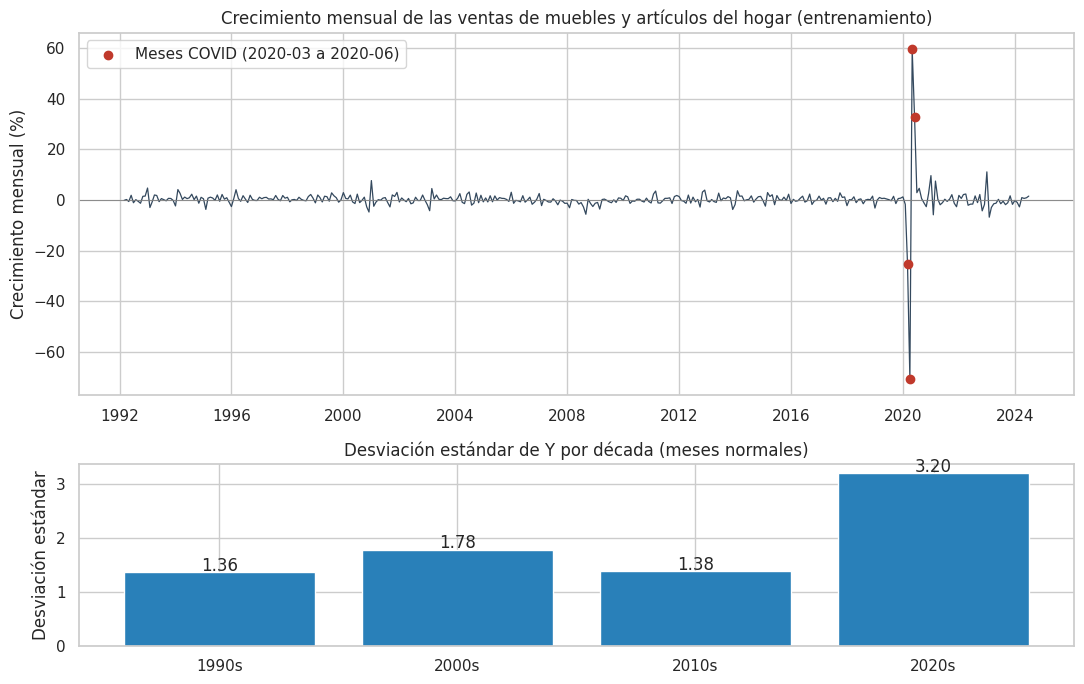

   [figura guardada] fig_B1_serie_tiempo.png

Coeficiente de variación de Y por década (meses normales, %):
        desv_std_meses_normales  coef_variacion_%
decada                                           
1990s                     1.362            242.75
2000s                     1.777          -5836.78
2010s                     1.381            442.77
2020s                     3.202           3198.79
   [tabla guardada] tabla_cv_por_decada.csv
   [tabla guardada] tabla_desv_por_decada.csv
Desviación estándar por década (meses normales):
decada
1990s    1.36
2000s    1.78
2010s    1.38
2020s    3.20

Antes de 2020-03: desv. std = 1.54 (336 meses)
Desde 2020-07:    desv. std = 3.25 (49 meses)
Cociente de desviaciones (después/antes) = 2.10
Prueba de Levene (igualdad de varianzas): estadístico = 31.20, p = 4.42e-08


In [ ]:
titulo("5.6 Serie de tiempo y volatilidad")

cov = entren[entren["es_covid"]]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(entren["fecha"], entren[Y], color="#34495e", lw=0.9)
ax[0].scatter(cov["fecha"], cov[Y], color="#c0392b", zorder=3, label="Meses COVID (2020-03 a 2020-06)")
ax[0].axhline(0, color="gray", lw=0.6)
ax[0].set_title("Crecimiento mensual de las ventas de muebles y artículos del hogar (entrenamiento)")
ax[0].set_ylabel("Crecimiento mensual (%)")
ax[0].legend()

sd_dec = normales.groupby("decada")[Y].std()
ax[1].bar(sd_dec.index, sd_dec.values, color="#2980b9")
ax[1].set_title("Desviación estándar de Y por década (meses normales)")
ax[1].set_ylabel("Desviación estándar")
for i, v in enumerate(sd_dec.values):
    ax[1].text(i, v + 0.03, f"{v:.2f}", ha="center")
guardar_figura("fig_B1_serie_tiempo.png")

media_dec = normales.groupby("decada")[Y].mean()
cv_dec = (sd_dec / media_dec.reindex(sd_dec.index)) * 100
cv_tab = pd.DataFrame({
    "desv_std_meses_normales": sd_dec.round(3),
    "coef_variacion_%": cv_dec.round(2),
})
print("\nCoeficiente de variación de Y por década (meses normales, %):")
print(cv_tab.to_string())
guardar_tabla(cv_tab, "tabla_cv_por_decada.csv")

guardar_tabla(sd_dec.round(3).to_frame("desv_std_meses_normales"), "tabla_desv_por_decada.csv")

antes = entren.loc[entren["fecha"] < "2020-03-01", Y]
despues = entren.loc[entren["fecha"] >= "2020-07-01", Y]
lev = stats.levene(antes, despues)
print("Desviación estándar por década (meses normales):")
print(sd_dec.round(2).to_string())
print(f"\nAntes de 2020-03: desv. std = {antes.std():.2f} ({len(antes)} meses)")
print(f"Desde 2020-07:    desv. std = {despues.std():.2f} ({len(despues)} meses)")
print(f"Cociente de desviaciones (después/antes) = {despues.std() / antes.std():.2f}")
print(f"Prueba de Levene (igualdad de varianzas): estadístico = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

### 5.7 Boxplots

Los boxplots permiten ver la variabilidad entre grupos y los valores atípicos. En este proyecto no hay regiones ni modelos de producto, así que el grupo natural es la década. El panel izquierdo muestra la respuesta por década, con y sin los meses de COVID, y el derecho muestra todas las variables explicativas estandarizadas para compararlas en una sola escala. Los puntos fuera de los bigotes son valores atípicos según la regla de Tukey (más de 1.5 veces el rango intercuartil).


5.7 Boxplots


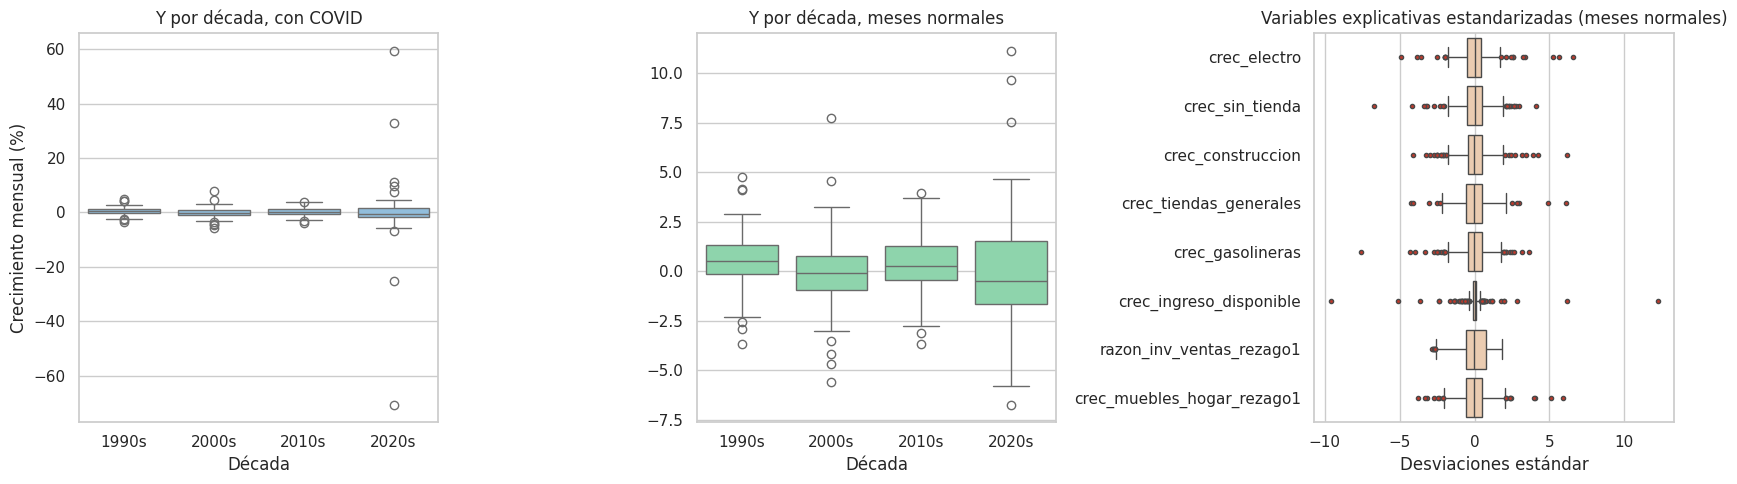

   [figura guardada] fig_B2_boxplots.png
Valores atípicos de Y por la regla de Tukey (meses normales): 16 de 384 (límites -3.69 y 4.05)


In [ ]:
titulo("5.7 Boxplots")

orden = sorted(entren["decada"].unique())
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=entren, x="decada", y=Y, order=orden, ax=ax[0], color="#85c1e9")
ax[0].set_title("Y por década, con COVID")
ax[0].set_xlabel("Década"); ax[0].set_ylabel("Crecimiento mensual (%)")
sns.boxplot(data=normales, x="decada", y=Y, order=orden, ax=ax[1], color="#82e0aa")
ax[1].set_title("Y por década, meses normales")
ax[1].set_xlabel("Década"); ax[1].set_ylabel("")
z = (normales[X] - normales[X].mean()) / normales[X].std()
sns.boxplot(data=z, orient="h", ax=ax[2], color="#f5cba7",
            flierprops=dict(marker="o", markersize=3, markerfacecolor="#c0392b"))
ax[2].set_title("Variables explicativas estandarizadas (meses normales)")
ax[2].set_xlabel("Desviaciones estándar")
guardar_figura("fig_B2_boxplots.png")

q1, q3 = normales[Y].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((normales[Y] < lim_inf) | (normales[Y] > lim_sup)).sum())
print(f"Valores atípicos de Y por la regla de Tukey (meses normales): {n_out} de {len(normales)} "
      f"(límites {lim_inf:.2f} y {lim_sup:.2f})")

### 5.8 Dispersión con línea de tendencia

Cada gráfico enfrenta la respuesta con una variable explicativa. Se dibujan dos rectas, una con todos los puntos (roja) y otra solo con los meses normales (verde). Los puntos rojos son los meses de COVID. Se hacen dos versiones, una completa y otra con zoom sobre la nube de meses normales, porque los puntos de COVID quedan tan lejos que aplastan el resto.


5.8 Dispersión con tendencia


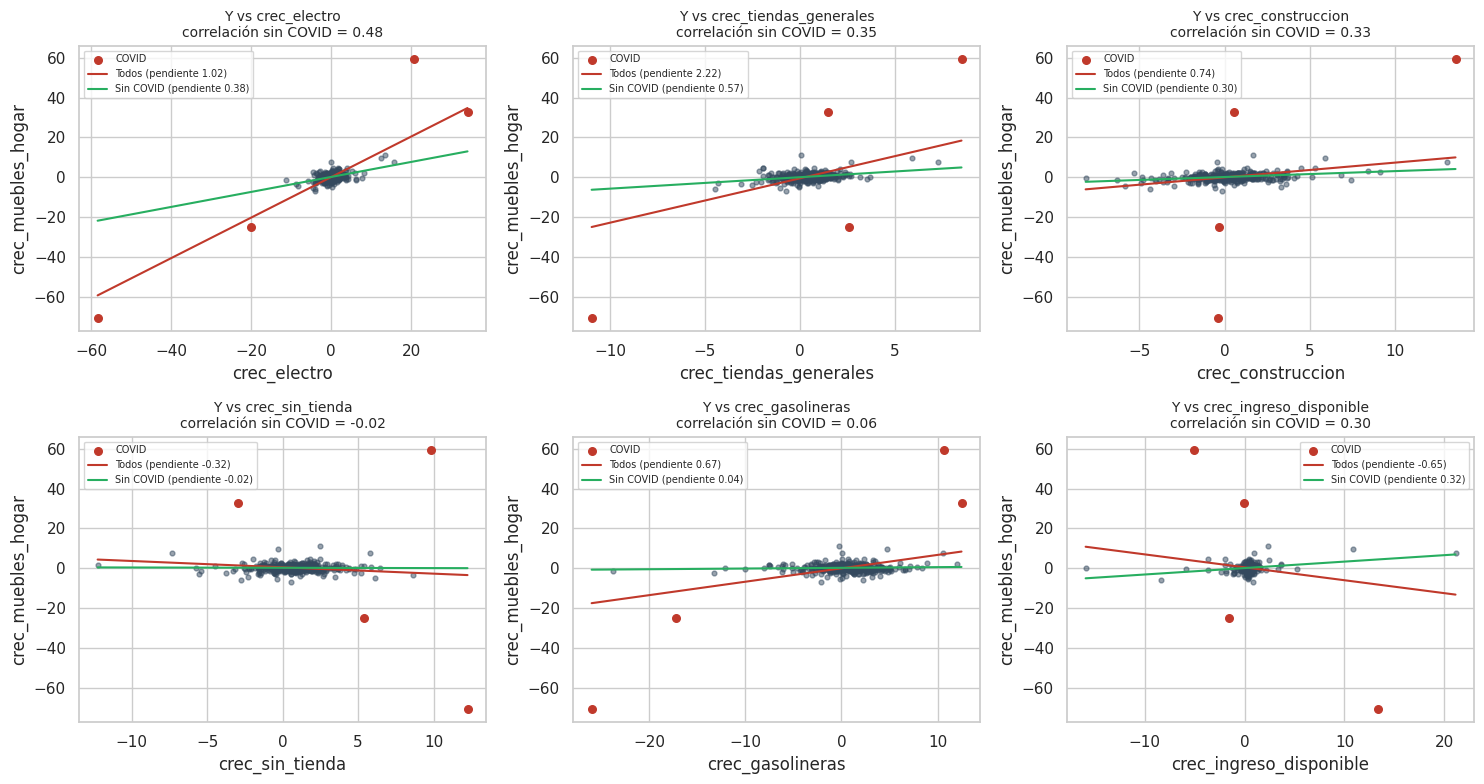

   [figura guardada] fig_B3_dispersion.png


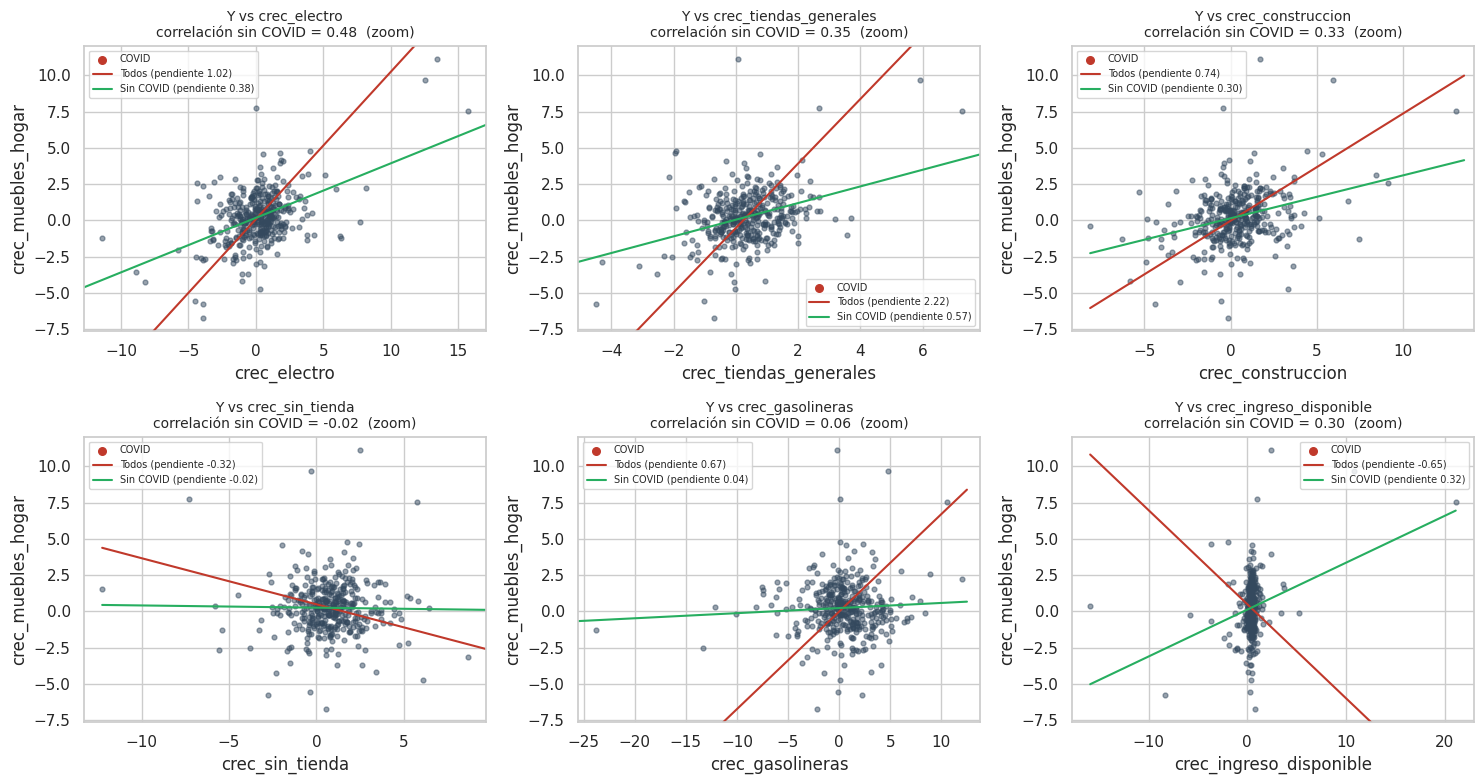

   [figura guardada] fig_B3_dispersion_zoom.png
   [tabla guardada] tabla_pendientes_dispersion.csv
                         pendiente_todos  pendiente_sin_covid  corr_sin_covid
crec_electro                       1.016                0.376           0.481
crec_tiendas_generales             2.225                0.574           0.355
crec_construccion                  0.741                0.296           0.331
crec_sin_tienda                   -0.318               -0.015          -0.016
crec_gasolineras                   0.673                0.035           0.061
crec_ingreso_disponible           -0.649                0.323           0.298


In [ ]:
titulo("5.8 Dispersión con tendencia")

vars_scatter = ["crec_electro", "crec_tiendas_generales", "crec_construccion",
                "crec_sin_tienda", "crec_gasolineras", "crec_ingreso_disponible"]
pend = {}
for zoom in (False, True):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, v in zip(axes.ravel(), vars_scatter):
        ax.scatter(normales[v], normales[Y], s=12, alpha=0.5, color="#34495e")
        ax.scatter(cov[v], cov[Y], s=30, color="#c0392b", label="COVID")
        xs = np.linspace(entren[v].min(), entren[v].max(), 100)
        b_all = np.polyfit(entren[v], entren[Y], 1)
        b_sin = np.polyfit(normales[v], normales[Y], 1)
        ax.plot(xs, np.polyval(b_all, xs), color="#c0392b", lw=1.5, label=f"Todos (pendiente {b_all[0]:.2f})")
        ax.plot(xs, np.polyval(b_sin, xs), color="#27ae60", lw=1.5, label=f"Sin COVID (pendiente {b_sin[0]:.2f})")
        r_sin = np.corrcoef(normales[v], normales[Y])[0, 1]
        ax.set_title(f"Y vs {v}\ncorrelación sin COVID = {r_sin:.2f}" + ("  (zoom)" if zoom else ""), fontsize=10)
        if zoom:
            mx_ = 0.05 * (normales[v].max() - normales[v].min())
            my_ = 0.05 * (normales[Y].max() - normales[Y].min())
            ax.set_xlim(normales[v].min() - mx_, normales[v].max() + mx_)
            ax.set_ylim(normales[Y].min() - my_, normales[Y].max() + my_)
        ax.set_xlabel(v); ax.set_ylabel(Y)
        ax.legend(fontsize=7)
        pend[v] = {"pendiente_todos": b_all[0], "pendiente_sin_covid": b_sin[0], "corr_sin_covid": r_sin}
    guardar_figura("fig_B3_dispersion_zoom.png" if zoom else "fig_B3_dispersion.png")
guardar_tabla(pd.DataFrame(pend).T.round(3), "tabla_pendientes_dispersion.csv")
print(pd.DataFrame(pend).T.round(3).to_string())

### 5.9 Histogramas y gráficos de densidad

El histograma con la curva de densidad estimada (KDE) permite ver la forma de cada distribución. Primero se muestra la respuesta con y sin COVID, y después todas las variables en meses normales. Aquí la pregunta de fondo para el enfoque bayesiano es qué distribución usar en la verosimilitud: Normal, Poisson, Gamma o Log-Normal.


5.9 Histogramas y KDE


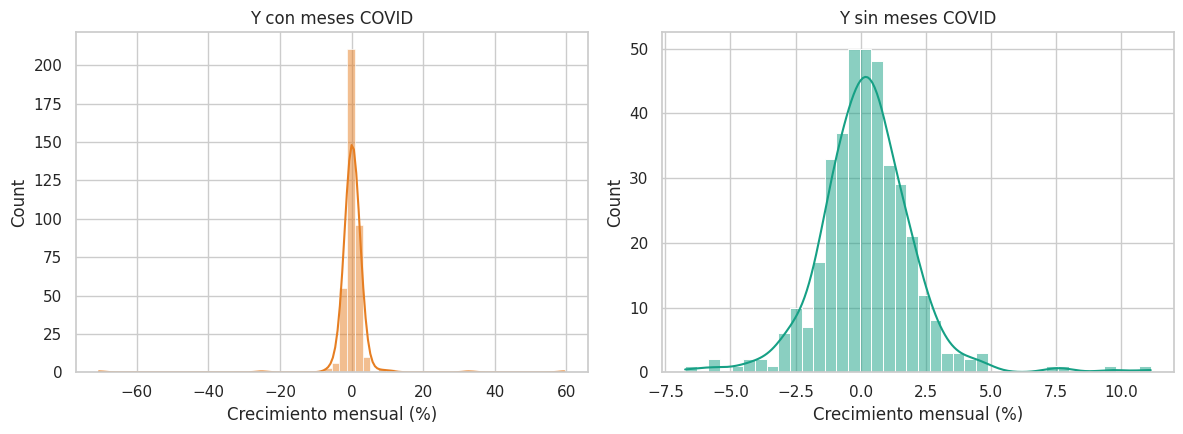

   [figura guardada] fig_B4_hist_kde_Y.png


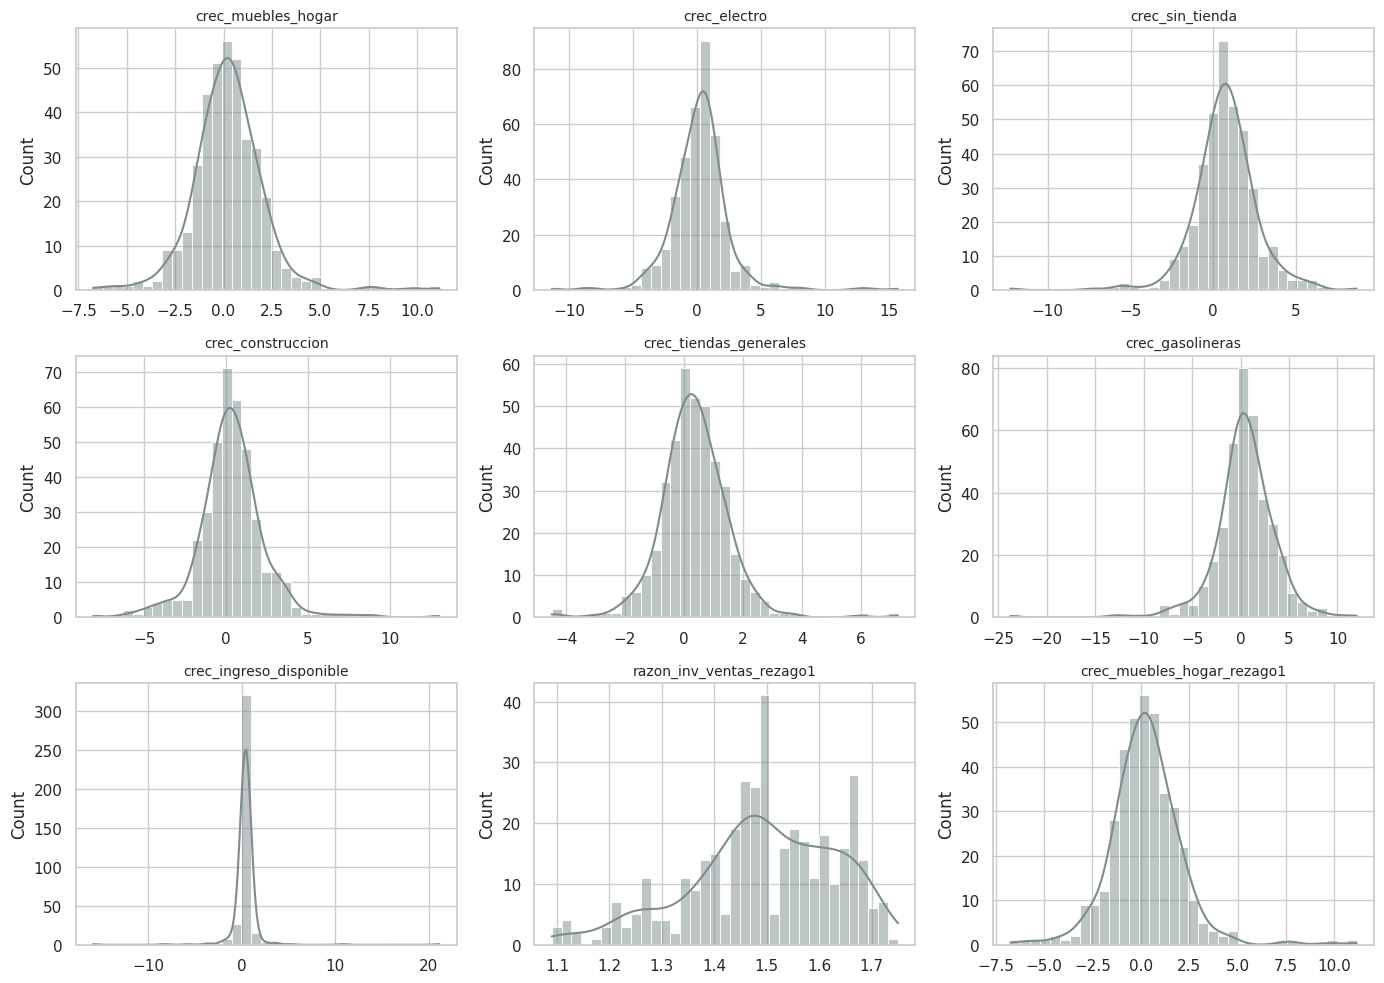

   [figura guardada] fig_B4_hist_kde_variables.png
Y toma valores negativos en 172 de 389 meses.
Por eso Poisson, Gamma y Log-Normal, que solo admiten valores positivos, no sirven para modelar Y.


In [ ]:
titulo("5.9 Histogramas y KDE")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(entren[Y], bins=60, kde=True, ax=ax[0], color="#e67e22")
ax[0].set_title("Y con meses COVID")
sns.histplot(normales[Y], bins=40, kde=True, ax=ax[1], color="#16a085")
ax[1].set_title("Y sin meses COVID")
for a in ax:
    a.set_xlabel("Crecimiento mensual (%)")
guardar_figura("fig_B4_hist_kde_Y.png")

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for a, v in zip(axes.ravel(), CUANTI):
    sns.histplot(normales[v], bins=35, kde=True, ax=a, color="#7f8c8d")
    a.set_title(v, fontsize=10)
    a.set_xlabel("")
guardar_figura("fig_B4_hist_kde_variables.png")

neg = int((entren[Y] < 0).sum())
print(f"Y toma valores negativos en {neg} de {len(entren)} meses.")
print("Por eso Poisson, Gamma y Log-Normal, que solo admiten valores positivos, no sirven para modelar Y.")

### 5.10 Elección de la distribución de la verosimilitud

Se ajustan tres distribuciones a la respuesta por máxima verosimilitud: Normal, t de Student y Laplace. Se comparan con el AIC, que premia el ajuste y castiga la cantidad de parámetros (menor es mejor). También se hacen gráficos cuantil-cuantil (QQ), donde los puntos deben seguir la diagonal si la distribución es la correcta, y la prueba de Shapiro-Wilk de normalidad, que rechaza normalidad cuando el valor p es muy pequeño.


5.10 Ajuste de distribuciones a Y
distribucion            parametros  log_verosimilitud    AIC   muestra
      Normal        (0.234, 5.449)            -1211.5 2426.9 con COVID
   Student-t (2.186, 0.199, 1.138)             -794.1 1594.1 con COVID
     Laplace        (0.233, 1.756)             -877.7 1759.3 con COVID
      Normal        (0.238, 1.839)             -778.7 1561.4 sin COVID
   Student-t (3.624, 0.196, 1.243)             -740.3 1486.5 sin COVID
     Laplace        (0.227, 1.282)             -745.6 1495.1 sin COVID
   [tabla guardada] tabla_ajuste_distribuciones.csv
Shapiro-Wilk (con COVID): p = 2.54e-35
Shapiro-Wilk (sin COVID): p = 4.79e-13


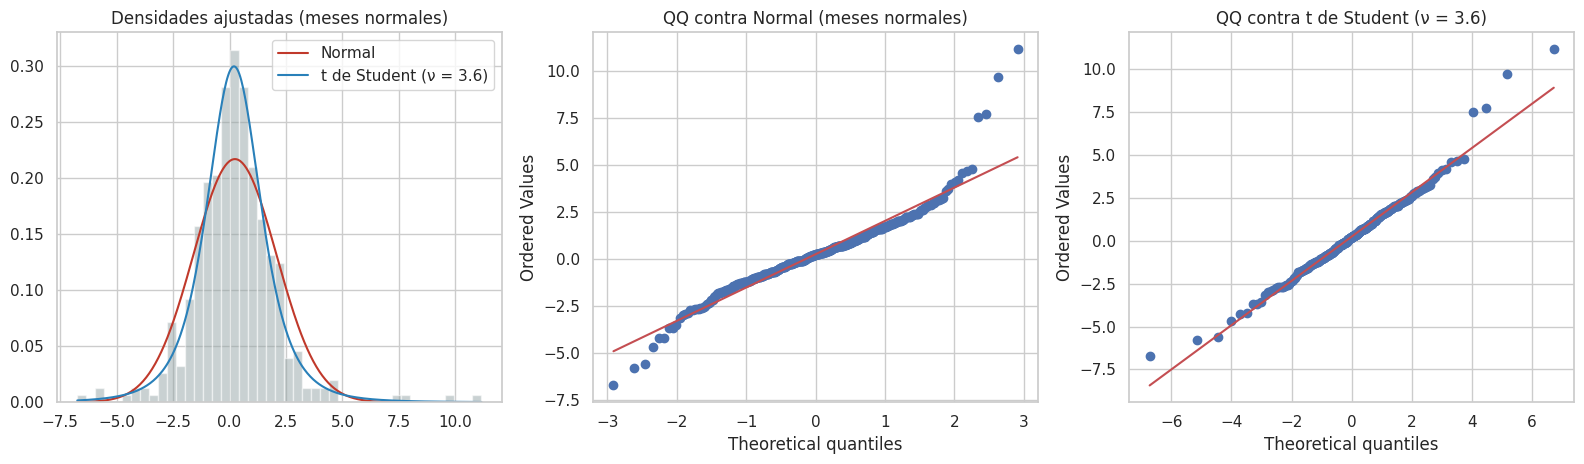

   [figura guardada] fig_B5_ajuste_distribuciones.png


In [ ]:
titulo("5.10 Ajuste de distribuciones a Y")


def ajustar(y):
    filas = []
    for nombre, dist, k in [("Normal", stats.norm, 2), ("Student-t", stats.t, 3), ("Laplace", stats.laplace, 2)]:
        par = dist.fit(y)
        ll = float(np.sum(dist.logpdf(y, *par)))
        filas.append({"distribucion": nombre, "parametros": tuple(round(float(p), 3) for p in par),
                      "log_verosimilitud": round(ll, 1), "AIC": round(2 * k - 2 * ll, 1)})
    return pd.DataFrame(filas)


ajustes = pd.concat([ajustar(entren[Y].values).assign(muestra="con COVID"),
                     ajustar(normales[Y].values).assign(muestra="sin COVID")], ignore_index=True)
print(ajustes.to_string(index=False))
guardar_tabla(ajustes, "tabla_ajuste_distribuciones.csv", indice=False)
for etiqueta, d in [("con COVID", entren), ("sin COVID", normales)]:
    print(f"Shapiro-Wilk ({etiqueta}): p = {stats.shapiro(d[Y]).pvalue:.2e}")

y_n = normales[Y].values
nu_n, loc_n, esc_n = stats.t.fit(y_n)
mu_n, sd_n = stats.norm.fit(y_n)
grid = np.linspace(y_n.min(), y_n.max(), 400)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].hist(y_n, bins=45, density=True, alpha=0.5, color="#95a5a6")
ax[0].plot(grid, stats.norm.pdf(grid, mu_n, sd_n), color="#c0392b", label="Normal")
ax[0].plot(grid, stats.t.pdf(grid, nu_n, loc_n, esc_n), color="#2980b9", label=f"t de Student (ν = {nu_n:.1f})")
ax[0].set_title("Densidades ajustadas (meses normales)")
ax[0].legend()
stats.probplot(y_n, dist="norm", plot=ax[1])
ax[1].set_title("QQ contra Normal (meses normales)")
stats.probplot(y_n, dist=stats.t, sparams=(nu_n,), plot=ax[2])
ax[2].set_title(f"QQ contra t de Student (ν = {nu_n:.1f})")
guardar_figura("fig_B5_ajuste_distribuciones.png")

### 5.11 Matriz de correlaciones

Se grafican las correlaciones de Pearson entre todas las variables cuantitativas, con COVID a la izquierda y sin COVID a la derecha. Sirve para ver qué variables se relacionan con la respuesta y si las explicativas se parecen entre sí, lo que causaría problemas de colinealidad.


5.11 Matriz de correlaciones (Pearson)


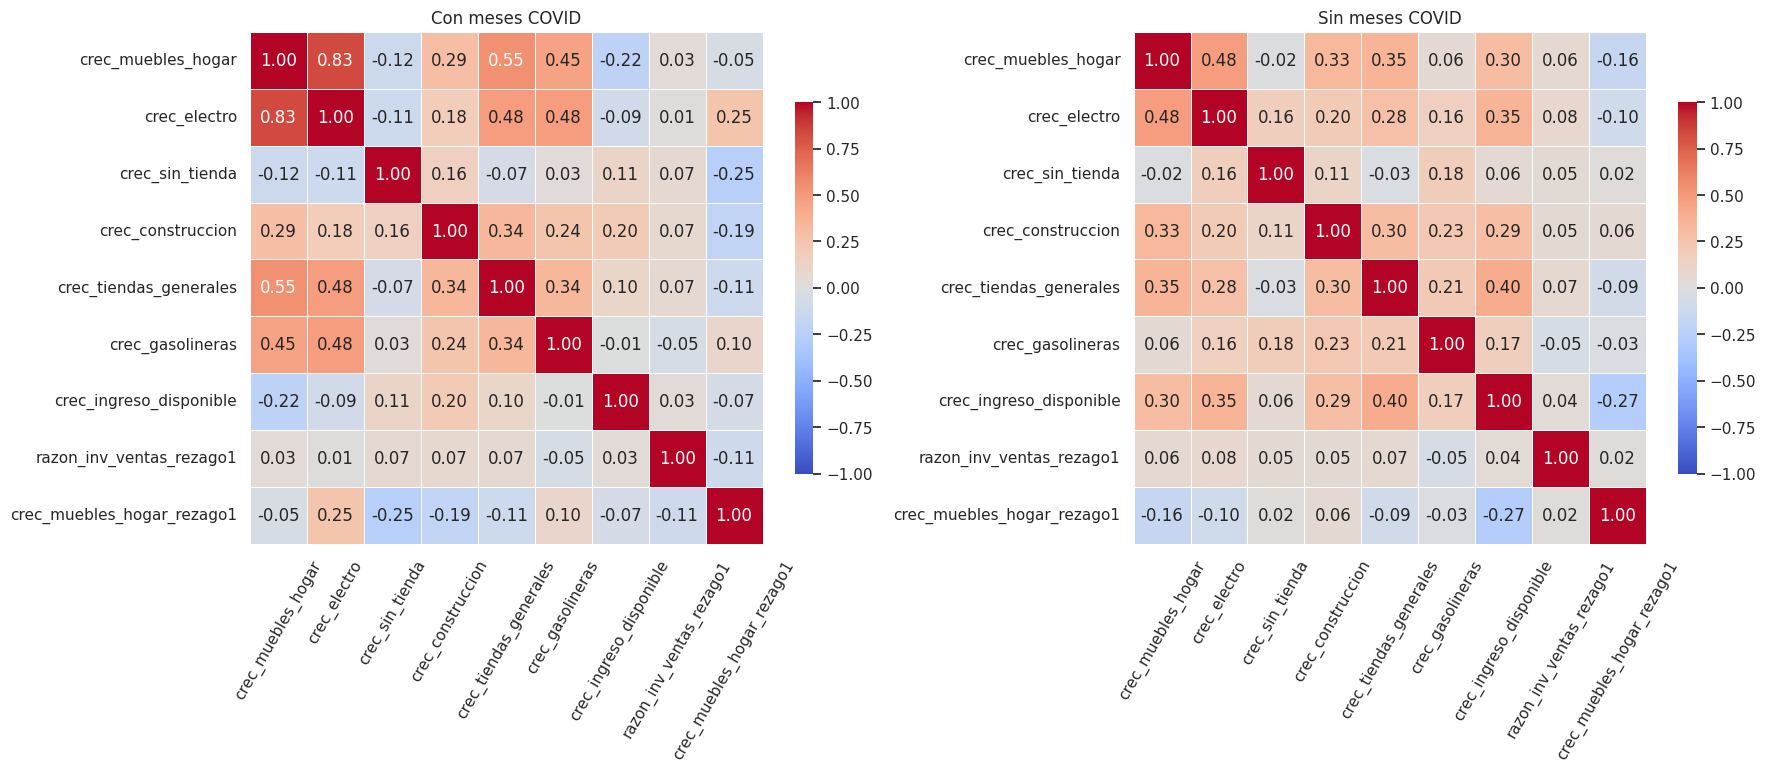

   [figura guardada] fig_B6_heatmap_correlaciones.png
   [tabla guardada] tabla_correlaciones_con_covid.csv
   [tabla guardada] tabla_correlaciones_sin_covid.csv
Correlación de cada variable con Y:
                            con_COVID  sin_COVID
crec_electro                     0.83       0.48
crec_tiendas_generales           0.55       0.35
crec_construccion                0.29       0.33
crec_ingreso_disponible         -0.22       0.30
razon_inv_ventas_rezago1         0.03       0.06
crec_gasolineras                 0.45       0.06
crec_sin_tienda                 -0.12      -0.02
crec_muebles_hogar_rezago1      -0.05      -0.16


In [ ]:
titulo("5.11 Matriz de correlaciones (Pearson)")

corr_con = entren[CUANTI].corr()
corr_sin = normales[CUANTI].corr()
fig, ax = plt.subplots(1, 2, figsize=(18, 7.5))
for a, c, t in [(ax[0], corr_con, "Con meses COVID"), (ax[1], corr_sin, "Sin meses COVID")]:
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
                linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=a)
    a.set_title(t)
    a.tick_params(axis="x", rotation=60)
guardar_figura("fig_B6_heatmap_correlaciones.png")
guardar_tabla(corr_con.round(3), "tabla_correlaciones_con_covid.csv")
guardar_tabla(corr_sin.round(3), "tabla_correlaciones_sin_covid.csv")

comp = pd.DataFrame({"con_COVID": corr_con[Y], "sin_COVID": corr_sin[Y]}).drop(index=Y).round(2)
print("Correlación de cada variable con Y:")
print(comp.sort_values("sin_COVID", ascending=False).to_string())

### 5.12 Autocorrelación (ACF y PACF)

Como los datos son una serie de tiempo, hay que revisar si el crecimiento de un mes se relaciona con el de meses anteriores. La ACF mide la correlación de la serie con sus propios rezagos, y la PACF lo mismo pero descontando el efecto de los rezagos intermedios. Las líneas rojas son bandas de ±1.96/√n: barras fuera de ellas indican autocorrelación distinta de cero.


5.12 Autocorrelación


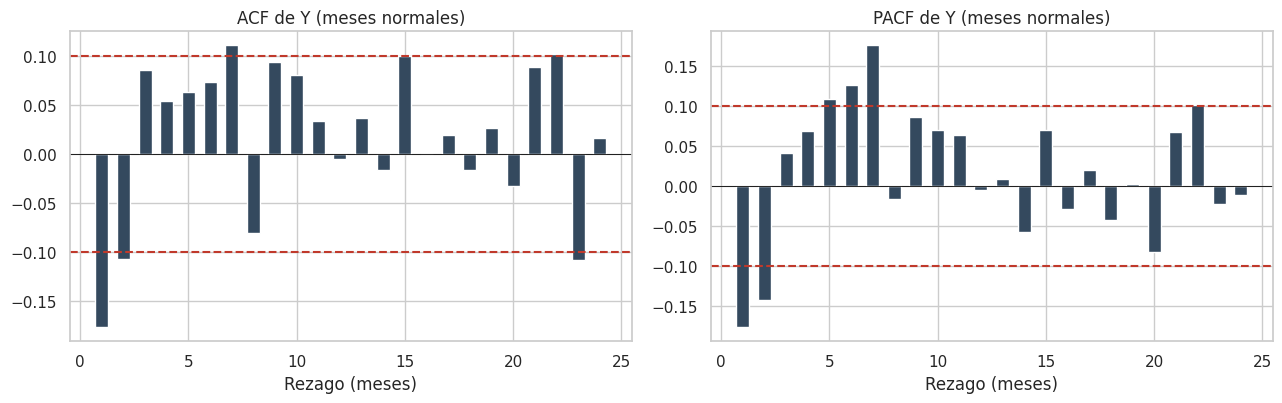

   [figura guardada] fig_B7_acf_pacf.png
Autocorrelación en el rezago 1: -0.18 | rezago 12: -0.00
Banda de ±0.10. Rezagos fuera de la banda: [1, 2, 7, 15, 22, 23]


In [ ]:
titulo("5.12 Autocorrelación")


def acf(x, nlags):
    x = np.asarray(x) - np.mean(x)
    den = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[: len(x) - k]) / den for k in range(nlags + 1)])


def pacf(x, nlags):
    r = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    salida = [1.0, r[1]]
    phi[1, 1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - sum(phi[k - 1, j] * r[k - j] for j in range(1, k))
        den = 1 - sum(phi[k - 1, j] * r[j] for j in range(1, k))
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        salida.append(phi[k, k])
    return np.array(salida)


NLAGS = 24
y_acf = normales[Y].values
banda = 1.96 / np.sqrt(len(y_acf))
a_vals, p_vals = acf(y_acf, NLAGS), pacf(y_acf, NLAGS)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, vals, t in [(ax[0], a_vals, "ACF de Y (meses normales)"), (ax[1], p_vals, "PACF de Y (meses normales)")]:
    a.bar(range(1, NLAGS + 1), vals[1:], color="#34495e", width=0.6)
    a.axhline(banda, color="#c0392b", ls="--")
    a.axhline(-banda, color="#c0392b", ls="--")
    a.axhline(0, color="black", lw=0.6)
    a.set_title(t)
    a.set_xlabel("Rezago (meses)")
guardar_figura("fig_B7_acf_pacf.png")
fuera = [k for k in range(1, NLAGS + 1) if abs(a_vals[k]) > banda]
print(f"Autocorrelación en el rezago 1: {a_vals[1]:.2f} | rezago 12: {a_vals[12]:.2f}")
print(f"Banda de ±{banda:.2f}. Rezagos fuera de la banda: {fuera}")

### 5.13 Multicolinealidad (VIF)

El factor de inflación de la varianza (VIF) de una variable explicativa se calcula como 1 / (1 - R²), donde R² sale de regresar esa variable contra las demás. Una regla práctica es que valores por debajo de 5 son tranquilos. Lo calculamos porque, en un modelo de regresión múltiple bayesiano, la colinealidad infla la varianza posterior de los coeficientes y puede hacerlos inestables aunque el ajuste parezca bueno. Si hay colinealidad fuerte, la posterior de los coeficientes queda muy dispersa y correlacionada.

In [ ]:
titulo("5.13 VIF")


def calcular_vif(d):
    c = np.corrcoef(d[X].values.T)
    return pd.Series(np.diag(np.linalg.inv(c)), index=X)


vif = pd.DataFrame({"VIF_con_covid": calcular_vif(entren), "VIF_sin_covid": calcular_vif(normales)}).round(2)
print(vif.to_string())
guardar_tabla(vif, "tabla_vif.csv")


5.13 VIF
                            VIF_con_covid  VIF_sin_covid
crec_electro                         1.73           1.22
crec_sin_tienda                      1.12           1.08
crec_construccion                    1.27           1.21
crec_tiendas_generales               1.56           1.31
crec_gasolineras                     1.38           1.13
crec_ingreso_disponible              1.08           1.43
razon_inv_ventas_rezago1             1.02           1.02
crec_muebles_hogar_rezago1           1.26           1.11
   [tabla guardada] tabla_vif.csv


### 5.14 Resumen de hallazgos del EDA

Esta celda junta los números que se usan en el documento y los guarda en un archivo de texto. Sirve para no tener que copiarlos a mano desde las tablas.

In [ ]:
titulo("5.14 Resumen del EDA")

mejor = ajustes[ajustes["muestra"] == "sin COVID"].sort_values("AIC").iloc[0]["distribucion"]
lineas_eda = [
    f"Base: {len(df)} meses ({df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}). Entrenamiento: {len(entren)}; prueba reservada: {len(prueba)}.",
    f"Y con COVID: desviación {res_con.loc[Y, 'desv_std']}, asimetría {res_con.loc[Y, 'asimetria']}, curtosis en exceso {res_con.loc[Y, 'curtosis_exceso']}.",
    f"Y sin COVID: desviación {res_sin.loc[Y, 'desv_std']}, asimetría {res_sin.loc[Y, 'asimetria']}, curtosis en exceso {res_sin.loc[Y, 'curtosis_exceso']}.",
    "Desviación estándar de Y por década (meses normales): " + ", ".join(f"{k}: {v:.2f}" for k, v in sd_dec.items()) + ".",
    f"Antes de 2020-03 la desviación es {antes.std():.2f} y desde 2020-07 es {despues.std():.2f} (Levene p = {lev.pvalue:.1e}).",
    f"Distribución con menor AIC: {mejor}, con {nu_n:.1f} grados de libertad en meses normales. Poisson, Gamma y Log-Normal no aplican porque Y es negativa en {neg} meses.",
    f"Correlación con Y sin COVID: electrónica {corr_sin.loc[Y, 'crec_electro']:.2f}, tiendas generales {corr_sin.loc[Y, 'crec_tiendas_generales']:.2f}, "
    f"construcción {corr_sin.loc[Y, 'crec_construccion']:.2f}, ingreso {corr_sin.loc[Y, 'crec_ingreso_disponible']:.2f}, razón inventarios {corr_sin.loc[Y, 'razon_inv_ventas_rezago1']:.2f}.",
    f"VIF máximo (meses normales): {vif['VIF_sin_covid'].max()}.",
    f"Autocorrelación de Y en el rezago 1: {a_vals[1]:.2f}.",
]
for l in lineas_eda:
    print("- " + l)
(CARPETA_TABLAS / "resumen_eda.txt").write_text("\n".join(lineas_eda), encoding="utf-8")


5.14 Resumen del EDA
- Base: 413 meses (1992-03 a 2026-07). Entrenamiento: 389; prueba reservada: 24.
- Y con COVID: desviación 5.456, asimetría -2.022, curtosis en exceso 112.677.
- Y sin COVID: desviación 1.841, asimetría 0.861, curtosis en exceso 6.208.
- Desviación estándar de Y por década (meses normales): 1990s: 1.36, 2000s: 1.78, 2010s: 1.38, 2020s: 3.20.
- Antes de 2020-03 la desviación es 1.54 y desde 2020-07 es 3.25 (Levene p = 4.4e-08).
- Distribución con menor AIC: Student-t, con 3.6 grados de libertad en meses normales. Poisson, Gamma y Log-Normal no aplican porque Y es negativa en 172 meses.
- Correlación con Y sin COVID: electrónica 0.48, tiendas generales 0.35, construcción 0.33, ingreso 0.30, razón inventarios 0.06.
- VIF máximo (meses normales): 1.43.
- Autocorrelación de Y en el rezago 1: -0.18.


786

# Parte C. Primera especificación de las priors
(Numeral 6 del PDF. Se califica en Estadística Bayesiana.)

Con lo que mostró el EDA se define el modelo, y para cada parámetro se da la distribución a priori, los hiperparámetros y el argumento. Después se comprueba con una predictiva a priori que lo que se asume antes de ver los datos tenga sentido.

### 6.1 El modelo

Para cada mes $t$, la respuesta $y_t$ es el crecimiento mensual de las ventas de muebles y artículos del hogar, y $z_{jt}$ son las $j = 1, \dots, 8$ variables explicativas estandarizadas. El modelo es

$$y_t = \beta_0 + \sum_{j=1}^{8} \beta_j \, z_{jt} + \varepsilon_t, \qquad \varepsilon_t \sim t_{\nu}\big(0, \sigma_t\big)$$

La escala del error no es constante. Se escribe como

$$\sigma_t = \sigma \cdot \lambda_t \cdot \psi^{\,I(t \ge \text{jul-2020})}$$

donde $\lambda_t = \kappa_m$ en cada uno de los cuatro meses de COVID (marzo, abril, mayo y junio de 2020) y $\lambda_t = 1$ en los demás meses, y $\psi$ es un factor que permite que la volatilidad cambie desde julio de 2020.

Las razones de cada decisión salen del EDA. La t de Student se usa porque la respuesta tiene colas pesadas incluso sin COVID (secciones 5.9 y 5.10). Los factores $\kappa_m$ se usan para conservar los cuatro meses de COVID sin que deformen los demás parámetros, siguiendo la idea de Lenza y Primiceri (2022) de modelar el cambio de volatilidad de la pandemia en lugar de eliminar esos meses, lo cual subestima la incertidumbre. El factor $\psi$ se usa porque la volatilidad desde 2020 es más del doble que la anterior (sección 5.6). Los parámetros son entonces $\beta_0$, $\beta_1, \dots, \beta_8$, $\sigma$, $\nu$, $\kappa_1, \dots, \kappa_4$ y $\psi$, 16 en total.

Las variables explicativas se estandarizan con la media y la desviación de los meses normales del entrenamiento, y no con las de toda la muestra, para que una unidad signifique una desviación estándar en condiciones normales y no una desviación inflada por los meses de COVID. Esto se hace solo con datos de entrenamiento, para no filtrar información de la prueba.

In [ ]:
titulo("6.2 Datos de entrenamiento y estandarización")

media_x = normales[X].mean()
desv_x = normales[X].std(ddof=0)
Z = np.column_stack([np.ones(len(entren)), ((entren[X] - media_x) / desv_x).values])
y = entren[Y].values
idx_covid = np.where(entren["es_covid"].values)[0]                       # los 4 meses COVID
post = (entren["fecha"] >= pd.Timestamp("2020-07-01")).values.astype(float)   # 1 desde julio de 2020
mask_normal = ~entren["es_covid"].values

estand = pd.DataFrame({"media_meses_normales": media_x, "desv_meses_normales": desv_x}).round(4)
print(estand.to_string())
print(f"\nMatriz de diseño Z: {Z.shape} (intercepto y {len(X)} variables estandarizadas)")
print(f"Meses COVID: {len(idx_covid)} | meses desde julio de 2020: {int(post.sum())}")
print(f"Desviación de Y: {y.std():.2f} con COVID, {y[mask_normal].std():.2f} sin los 4 meses COVID")
guardar_tabla(estand, "tabla_estandarizacion.csv")


6.2 Datos de entrenamiento y estandarización
                            media_meses_normales  desv_meses_normales
crec_electro                              0.1910               2.3512
crec_sin_tienda                           0.7229               1.9283
crec_construccion                         0.3284               2.0567
crec_tiendas_generales                    0.3459               1.1360
crec_gasolineras                          0.4224               3.1772
crec_ingreso_disponible                   0.3818               1.6940
razon_inv_ventas_rezago1                  1.4916               0.1409
crec_muebles_hogar_rezago1                0.2519               1.8424

Matriz de diseño Z: (389, 9) (intercepto y 8 variables estandarizadas)
Meses COVID: 4 | meses desde julio de 2020: 49
Desviación de Y: 5.45 con COVID, 1.84 sin los 4 meses COVID
   [tabla guardada] tabla_estandarizacion.csv


### 6.3 Tabla de priors

Esta es la tabla que va en el documento. Los hiperparámetros no se ajustaron para que la posterior salga de cierta forma. Para elegirlos se usó solo el orden de magnitud de la respuesta (desviación de unos 1.8 puntos en meses normales), que es el tipo de información que se considera legítima al construir priors débilmente informativas.

In [ ]:
titulo("6.3 Especificación de las priors")

PRIORS = {
    "beta0": stats.norm(0, 1),
    "beta": stats.norm(0, 1),
    "sigma": stats.halfnorm(scale=2),
    "nu": stats.gamma(a=2, scale=1 / 0.1),
    "log_kappa": stats.halfnorm(scale=2),
    "log_psi": stats.norm(0, 1),
}

tabla_priors = pd.DataFrame([
    ["β0 (intercepto)", "Normal", "media 0, desviación 1",
     "El crecimiento medio mensual de las ventas de muebles es pequeño, cercano a 0.2 puntos. Un intercepto centrado en 0 con desviación 1 cubre valores entre -2 y 2 sin imponer ninguno."],
    ["βj, j = 1 a 8 (variables estandarizadas)", "Normal", "media 0, desviación 1",
     "Un cambio de una desviación estándar en otra categoría del comercio, o en el ingreso, no debería mover las ventas de muebles más de un par de puntos, que es la escala de Y en meses normales. Con desviación 1, la probabilidad a priori de |β| > 2 es de 4.6%. Se centra en 0 para no imponer el signo. Gelman et al. (2008) proponen priors débilmente informativas de este tipo para coeficientes de variables estandarizadas."],
    ["σ (escala del error)", "Half-Normal", "escala 2",
     "σ debe ser positiva. Con escala 2 la mediana a priori es de 1.35 y el intervalo del 90% es [0.13, 3.92], que cubre la desviación de Y en meses normales (1.8) y valores menores, esperables después de explicar parte de la variación con las X. Gelman (2006) recomienda priors débilmente informativas sobre los parámetros de escala."],
    ["ν (grados de libertad de la t)", "Gamma", "forma 2, tasa 0.1 (media 20)",
     "Permite desde colas muy pesadas (ν < 5 tiene 9% de probabilidad) hasta casi una normal (ν > 30 tiene 20%). Es la opción por defecto propuesta por Juárez y Steel (2010) para los grados de libertad de una t. El EDA sugiere un ν bajo, pero no se usa para fijar la prior."],
    ["κm, m = 1 a 4 (escala extra en mar-jun 2020)", "log κm ~ Half-Normal", "escala 2 (κm ≥ 1)",
     "Multiplica la escala del error en cada mes de COVID, siguiendo la idea de Lenza y Primiceri (2022). Se pone sobre el logaritmo para que κ sea siempre mayor o igual a 1 y para que permita factores pequeños (mediana 3.9) o muy grandes (percentil 95 cercano a 50), porque los meses de COVID se alejaron entre 14 y 39 desviaciones estándar de un mes normal."],
    ["ψ (cambio de escala desde jul-2020)", "log ψ ~ Normal", "media 0, desviación 1",
     "Centrado en ψ = 1 (sin cambio), porque a priori no sabemos si la volatilidad subió o bajó. Con desviación 1, ψ puede ir de 0.14 a 7 con 95% de probabilidad. El EDA muestra que la volatilidad es más del doble desde 2020 (secciones 5.6 y 5.7), lo que motiva incluir el parámetro, pero no se calibra con esa cifra."],
], columns=["parámetro", "distribución", "hiperparámetros", "argumento"])

pd.set_option("display.max_colwidth", 200)
for _, f in tabla_priors.iterrows():
    print(f"{f['parámetro']}\n  Distribución: {f['distribución']} | {f['hiperparámetros']}\n  Argumento: {f['argumento']}\n")
guardar_tabla(tabla_priors, "tabla_priors.csv", indice=False)

# cifras que se citan en los argumentos
print("Cifras de apoyo:")
print(f"  P(|beta| > 2) a priori = {2 * (1 - PRIORS['beta'].cdf(2)):.3f}")
print(f"  sigma: mediana {PRIORS['sigma'].median():.2f}, intervalo 90% [{PRIORS['sigma'].ppf(0.05):.2f}, {PRIORS['sigma'].ppf(0.95):.2f}]")
print(f"  nu: media {PRIORS['nu'].mean():.0f}, P(nu < 2) = {PRIORS['nu'].cdf(2):.3f}, P(nu < 5) = {PRIORS['nu'].cdf(5):.3f}, P(nu > 30) = {1 - PRIORS['nu'].cdf(30):.3f}")
print(f"  kappa: mediana {np.exp(PRIORS['log_kappa'].median()):.1f}, percentil 90 {np.exp(PRIORS['log_kappa'].ppf(0.90)):.0f}, percentil 95 {np.exp(PRIORS['log_kappa'].ppf(0.95)):.0f}")
print(f"  psi: intervalo 95% [{np.exp(PRIORS['log_psi'].ppf(0.025)):.2f}, {np.exp(PRIORS['log_psi'].ppf(0.975)):.2f}]")


6.3 Especificación de las priors
β0 (intercepto)
  Distribución: Normal | media 0, desviación 1
  Argumento: El crecimiento medio mensual de las ventas de muebles es pequeño, cercano a 0.2 puntos. Un intercepto centrado en 0 con desviación 1 cubre valores entre -2 y 2 sin imponer ninguno.

βj, j = 1 a 8 (variables estandarizadas)
  Distribución: Normal | media 0, desviación 1
  Argumento: Un cambio de una desviación estándar en otra categoría del comercio, o en el ingreso, no debería mover las ventas de muebles más de un par de puntos, que es la escala de Y en meses normales. Con desviación 1, la probabilidad a priori de |β| > 2 es de 4.6%. Se centra en 0 para no imponer el signo. Gelman et al. (2008) proponen priors débilmente informativas de este tipo para coeficientes de variables estandarizadas.

σ (escala del error)
  Distribución: Half-Normal | escala 2
  Argumento: σ debe ser positiva. Con escala 2 la mediana a priori es de 1.35 y el intervalo del 90% es [0.13, 3.92], que cubre

### 6.4 Gráficos de las priors

Las densidades muestran la forma de lo que asumimos antes de ver los datos. Van en el documento para que el lector vea qué tan amplias o concentradas son.


6.4 Gráficos de las priors


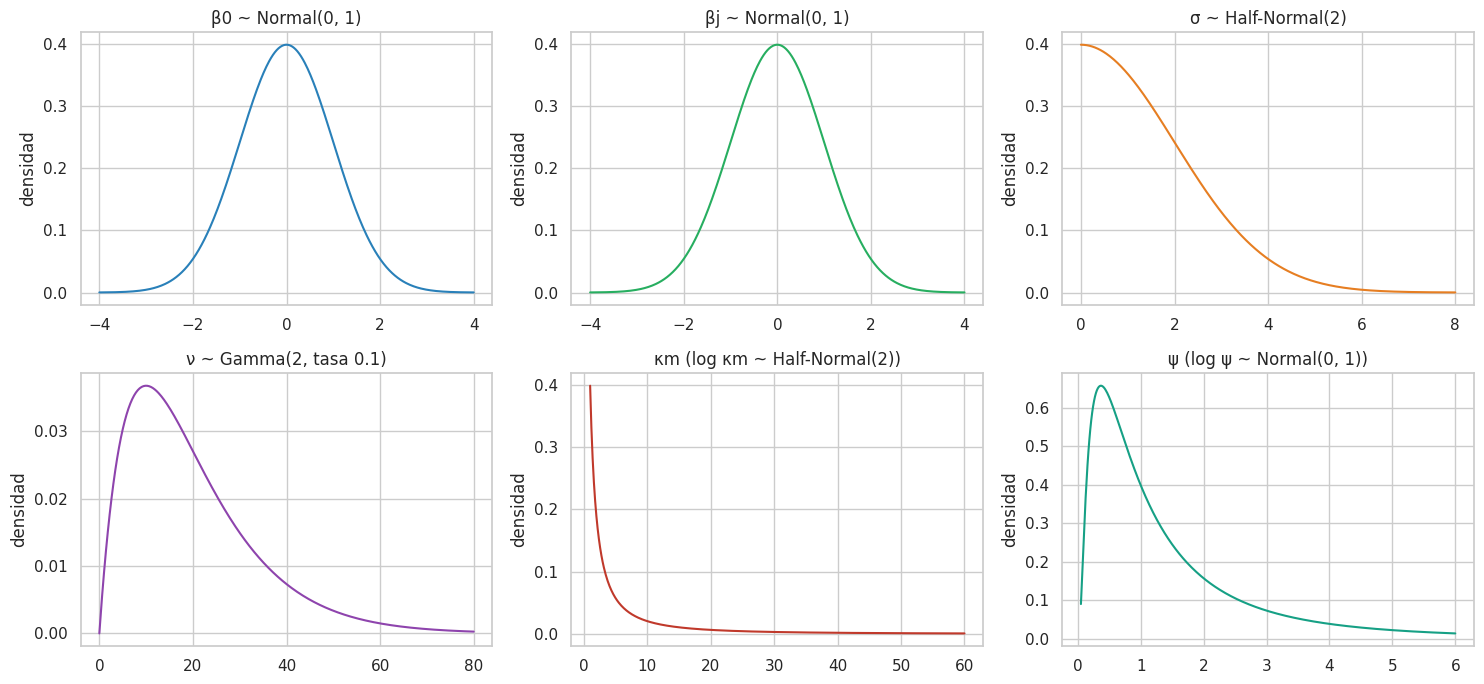

   [figura guardada] fig_C1_densidades_priors.png


In [ ]:
titulo("6.4 Gráficos de las priors")

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
g = np.linspace(-4, 4, 400)
ax[0, 0].plot(g, PRIORS["beta0"].pdf(g), color="#2980b9"); ax[0, 0].set_title("β0 ~ Normal(0, 1)")
ax[0, 1].plot(g, PRIORS["beta"].pdf(g), color="#27ae60"); ax[0, 1].set_title("βj ~ Normal(0, 1)")
gs = np.linspace(0, 8, 400)
ax[0, 2].plot(gs, PRIORS["sigma"].pdf(gs), color="#e67e22"); ax[0, 2].set_title("σ ~ Half-Normal(2)")
gn = np.linspace(0, 80, 400)
ax[1, 0].plot(gn, PRIORS["nu"].pdf(gn), color="#8e44ad"); ax[1, 0].set_title("ν ~ Gamma(2, tasa 0.1)")
gk = np.linspace(1, 60, 600)
dens_k = PRIORS["log_kappa"].pdf(np.log(gk)) / gk
ax[1, 1].plot(gk, dens_k, color="#c0392b"); ax[1, 1].set_title("κm (log κm ~ Half-Normal(2))")
gp = np.linspace(0.05, 6, 400)
ax[1, 2].plot(gp, PRIORS["log_psi"].pdf(np.log(gp)) / gp, color="#16a085"); ax[1, 2].set_title("ψ (log ψ ~ Normal(0, 1))")
for a in ax.ravel():
    a.set_ylabel("densidad")
guardar_figura("fig_C1_densidades_priors.png")

### 6.5 Chequeo predictivo a priori

La idea es simular parámetros desde las priors, y con ellos simular datos $y_t$ usando las variables explicativas reales. Si las priors son razonables, los datos simulados deben cubrir el rango de lo que se observa sin producir valores absurdos. Se evalúan por separado los meses normales, donde la simulación debe parecerse a una desviación de unos 1.8 puntos, y los meses de COVID, donde sí deben ser posibles valores muy extremos. Como la t con pocos grados de libertad produce valores gigantes, se reportan cuantiles y no máximos.


6.5 Chequeo predictivo a priori
Meses normales: cuantiles de y simulado contra y observado
     simulado  observado
1%     -11.00      -4.32
5%      -5.91      -2.59
25%     -2.05      -0.78
50%     -0.02       0.23
75%      2.01       1.16
95%      5.90       2.88
99%     11.07       5.21
   [tabla guardada] tabla_predictiva_priori_meses_normales.csv

Escala típica simulada en meses normales (rango intercuartil / 1.349): 2.82 | observada: 1.44
Proporción simulada con |y| < 10 en meses normales: 0.974 | observada: 0.997
Proporción simulada con |y| > 100 en meses normales: 0.0002

Meses COVID: valores observados [-25.1 -70.6  59.5  32.8]
P(|y| > 20) simulada en meses COVID: 0.527
P(|y| > 50) simulada en meses COVID: 0.195
P(|y| > 200) simulada en meses COVID: 0.0158


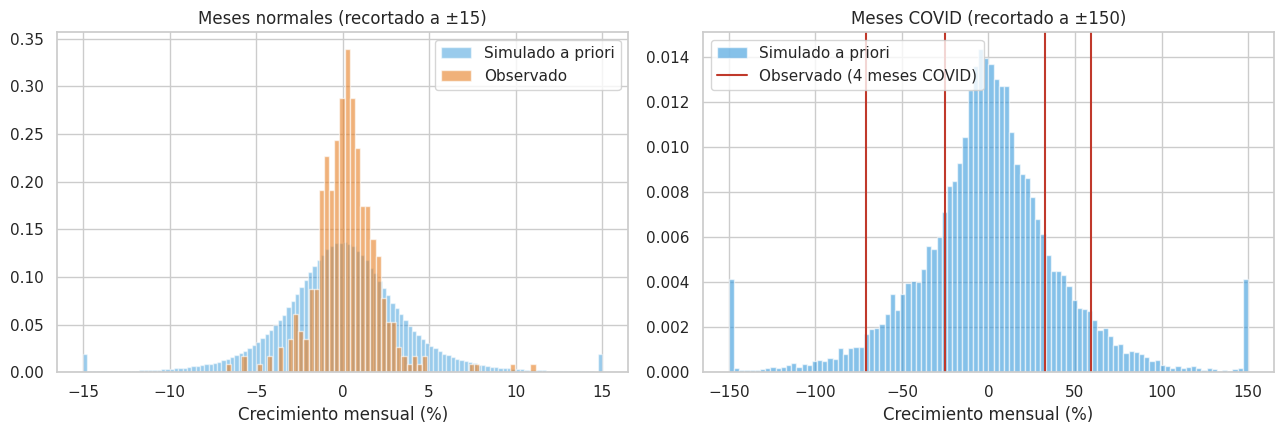

   [figura guardada] fig_C2_predictiva_priori.png


In [ ]:
titulo("6.5 Chequeo predictivo a priori")


def simular(n_sim, Zm, idx_cov, post_flag, priors, rng, prior_beta=None):
    # Simula n_sim vectores de y desde la predictiva a priori. Devuelve matriz n_sim x T.
    k = Zm.shape[1] - 1
    pb = prior_beta if prior_beta is not None else priors["beta"]
    b0 = priors["beta0"].rvs(n_sim, random_state=rng)
    b = pb.rvs((n_sim, k), random_state=rng)
    s = priors["sigma"].rvs(n_sim, random_state=rng)
    nu = np.maximum(priors["nu"].rvs(n_sim, random_state=rng), 0.5)
    lk = priors["log_kappa"].rvs((n_sim, len(idx_cov)), random_state=rng)
    lpsi = priors["log_psi"].rvs(n_sim, random_state=rng)
    mu = b0[:, None] + b @ Zm[:, 1:].T
    escala = s[:, None] * np.exp(lpsi[:, None] * post_flag[None, :])
    escala[:, idx_cov] *= np.exp(lk)
    return mu + rng.standard_t(nu[:, None], size=mu.shape) * escala


ysim = simular(N_SIM, Z, idx_covid, post, PRIORS, rng)
cuantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
sim_norm = ysim[:, mask_normal].ravel()
obs_norm = y[mask_normal]
tabla_pp = pd.DataFrame({"simulado": np.quantile(sim_norm, cuantiles),
                         "observado": np.quantile(obs_norm, cuantiles)}, index=[f"{int(c * 100)}%" for c in cuantiles]).round(2)
print("Meses normales: cuantiles de y simulado contra y observado")
print(tabla_pp.to_string())
guardar_tabla(tabla_pp, "tabla_predictiva_priori_meses_normales.csv")

escala_sim = np.median([stats.iqr(ysim[i, mask_normal]) / 1.349 for i in range(500)])
print(f"\nEscala típica simulada en meses normales (rango intercuartil / 1.349): {escala_sim:.2f} | observada: {stats.iqr(obs_norm) / 1.349:.2f}")
print(f"Proporción simulada con |y| < 10 en meses normales: {np.mean(np.abs(sim_norm) < 10):.3f} | observada: {np.mean(np.abs(obs_norm) < 10):.3f}")
print(f"Proporción simulada con |y| > 100 en meses normales: {np.mean(np.abs(sim_norm) > 100):.4f}")

sim_cov = ysim[:, idx_covid]
print("\nMeses COVID: valores observados", np.round(y[idx_covid], 1))
print(f"P(|y| > 20) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 20):.3f}")
print(f"P(|y| > 50) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 50):.3f}")
print(f"P(|y| > 200) simulada en meses COVID: {np.mean(np.abs(sim_cov) > 200):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lim = 15
ax[0].hist(np.clip(sim_norm, -lim, lim), bins=120, density=True, alpha=0.5, color="#3498db", label="Simulado a priori")
ax[0].hist(np.clip(obs_norm, -lim, lim), bins=60, density=True, alpha=0.6, color="#e67e22", label="Observado")
ax[0].set_title(f"Meses normales (recortado a ±{lim})"); ax[0].set_xlabel("Crecimiento mensual (%)"); ax[0].legend()
ax[1].hist(np.clip(sim_cov.ravel(), -150, 150), bins=100, density=True, alpha=0.6, color="#3498db", label="Simulado a priori")
for v in y[idx_covid]:
    ax[1].axvline(v, color="#c0392b", lw=1.5)
ax[1].axvline(np.nan, color="#c0392b", label="Observado (4 meses COVID)")
ax[1].set_title("Meses COVID (recortado a ±150)"); ax[1].set_xlabel("Crecimiento mensual (%)"); ax[1].legend()
guardar_figura("fig_C2_predictiva_priori.png")

### 6.6 Análisis de sensibilidad

Se repite el chequeo con otras priors para los coeficientes $\beta_j$: Normal(0, 0.5), la base Normal(0, 1), Normal(0, 2) y Cauchy(0, 2.5). Si las conclusiones no cambian mucho, la elección no es crítica. Lo que se mide es la escala simulada en meses normales y la probabilidad de valores desproporcionados.

In [ ]:
titulo("6.6 Sensibilidad")

alternativas = {
    "Normal(0, 0.5)": stats.norm(0, 0.5),
    "Normal(0, 1)  [base]": stats.norm(0, 1),
    "Normal(0, 2)": stats.norm(0, 2),
    "Cauchy(0, 2.5)": stats.cauchy(0, 2.5),
}
filas = []
for nombre, pri in alternativas.items():
    ys = simular(2000, Z, idx_covid, post, PRIORS, np.random.default_rng(SEMILLA), prior_beta=pri)
    sn = ys[:, mask_normal]
    filas.append({
        "prior_beta": nombre,
        "escala_tipica_meses_normales": round(float(np.median([stats.iqr(sn[i]) / 1.349 for i in range(500)])), 2),
        "prop_|y|<10": round(float(np.mean(np.abs(sn) < 10)), 3),
        "prop_|y|>100": round(float(np.mean(np.abs(sn) > 100)), 4),
    })
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))
print(f"\nReferencia observada en meses normales: escala {stats.iqr(obs_norm) / 1.349:.2f}, prop |y|<10 = {np.mean(np.abs(obs_norm) < 10):.3f}")
guardar_tabla(sens, "tabla_sensibilidad_priors.csv", indice=False)


6.6 Sensibilidad
          prior_beta  escala_tipica_meses_normales  prop_|y|<10  prop_|y|>100
      Normal(0, 0.5)                          2.07        0.985        0.0001
Normal(0, 1)  [base]                          2.95        0.973        0.0001
        Normal(0, 2)                          4.92        0.913        0.0002
      Cauchy(0, 2.5)                         16.32        0.456        0.0777

Referencia observada en meses normales: escala 1.44, prop |y|<10 = 0.997
   [tabla guardada] tabla_sensibilidad_priors.csv


### 6.7 Comprobación de plausibilidad con máxima verosimilitud

Se ajusta el mismo modelo por máxima verosimilitud con los datos de entrenamiento y se mira en qué parte de cada prior cae la estimación (el percentil). Si una estimación cae en un extremo de su prior, esa prior estaría dejando por fuera lo que dicen los datos. Esto solo es una comprobación y no se usa para fijar los hiperparámetros, porque eso sería usar los datos dos veces.

In [ ]:
titulo("6.7 Plausibilidad con máxima verosimilitud")


def nll_completo(p, yv, Zm, idx_cov, post_flag):
    k1 = Zm.shape[1]
    beta, ls, lnu = p[:k1], p[k1], p[k1 + 1]
    a = p[k1 + 2: k1 + 2 + len(idx_cov)]
    lpsi = p[-1]
    nu = np.exp(lnu)
    lam = np.zeros(len(yv))
    lam[idx_cov] = np.abs(a)                       # log kappa >= 0
    log_sc = ls + lpsi * post_flag + lam
    r = (yv - Zm @ beta) / np.exp(log_sc)
    ll = np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
                - log_sc - 0.5 * (nu + 1) * np.log1p(r * r / nu))
    return -ll


k1 = Z.shape[1]
inicio = np.r_[np.linalg.lstsq(Z, y, rcond=None)[0], 0.0, np.log(5.0), np.ones(len(idx_covid)) * 2.5, 0.0]
mejor_opt = None
for semilla in range(5):
    r0 = np.random.default_rng(semilla)
    p0 = inicio + np.r_[np.zeros(k1), r0.normal(0, 0.2, 2), r0.normal(0, 0.3, len(idx_covid)), r0.normal(0, 0.2)]
    o = optimize.minimize(nll_completo, p0, args=(y, Z, idx_covid, post), method="BFGS")
    if np.isfinite(o.fun) and (mejor_opt is None or o.fun < mejor_opt.fun):
        mejor_opt = o
p = mejor_opt.x
nombres_par = ["β0"] + [f"β({c})" for c in X] + ["σ", "ν"] + [f"κ{m + 1}" for m in range(len(idx_covid))] + ["ψ"]
est = np.r_[p[:k1], np.exp(p[k1]), np.exp(p[k1 + 1]), np.exp(np.abs(p[k1 + 2:k1 + 2 + len(idx_covid)])), np.exp(p[-1])]
cdf = np.r_[PRIORS["beta0"].cdf(p[0]), PRIORS["beta"].cdf(p[1:k1]), PRIORS["sigma"].cdf(est[k1]),
            PRIORS["nu"].cdf(est[k1 + 1]), PRIORS["log_kappa"].cdf(np.abs(p[k1 + 2:k1 + 2 + len(idx_covid)])),
            PRIORS["log_psi"].cdf(p[-1])]
plaus = pd.DataFrame({"estimación_MV": est.round(3), "percentil_en_la_prior": cdf.round(3)}, index=nombres_par)
plaus["comentario"] = np.where((plaus["percentil_en_la_prior"] < 0.005) | (plaus["percentil_en_la_prior"] > 0.995), "extremo", "dentro")
print(plaus.to_string())
print(f"\nParámetros en un extremo de su prior (percentil < 0.5% o > 99.5%): {int((plaus['comentario'] == 'extremo').sum())}")
guardar_tabla(plaus, "tabla_plausibilidad_mv.csv")


6.7 Plausibilidad con máxima verosimilitud
                               estimación_MV  percentil_en_la_prior comentario
β0                                     0.218                  0.586     dentro
β(crec_electro)                        0.623                  0.733     dentro
β(crec_sin_tienda)                    -0.067                  0.473     dentro
β(crec_construccion)                   0.403                  0.657     dentro
β(crec_tiendas_generales)              0.267                  0.605     dentro
β(crec_gasolineras)                   -0.184                  0.427     dentro
β(crec_ingreso_disponible)             0.110                  0.544     dentro
β(razon_inv_ventas_rezago1)            0.001                  0.500     dentro
β(crec_muebles_hogar_rezago1)         -0.108                  0.457     dentro
σ                                      1.145                  0.433     dentro
ν                                      6.181                  0.128     dentro
κ1      

# Parte D. Posterior con Metropolis-Hastings
(Numerales 7 y 8 del PDF. Se califica en Estadística Bayesiana.)

Con la verosimilitud y las priors definidas, la distribución posterior de los 16 parámetros no tiene forma cerrada, así que se aproxima con el algoritmo de Metropolis-Hastings. Esta parte define la posterior, corre cuatro cadenas desde puntos de inicio distintos, verifica la convergencia y resume el resultado. Todo se estima con los 389 meses de entrenamiento.

### 7.1 La log-posterior

Por el teorema de Bayes, la posterior es proporcional a la verosimilitud por las priors:

$$p(\theta \mid y) \;\propto\; \prod_{t=1}^{389} t_{\nu}\!\big(y_t \mid \mu_t,\, \sigma_t\big)\;\cdot\; p(\beta_0)\prod_{j=1}^{8} p(\beta_j)\; p(\sigma)\,p(\nu)\prod_{m=1}^{4} p(\kappa_m)\; p(\psi), \qquad \mu_t = \beta_0 + \sum_j \beta_j z_{jt}.$$

Para que las propuestas del algoritmo puedan moverse libremente, se muestrean $\log\sigma$, $\log\nu$ y $\log\psi$, y $u_m = \log\kappa_m$, que por su prior Half-Normal debe ser mayor o igual que 0. Al cambiar de variable se añade el jacobiano de cada transformación. Para comprobar que la función está bien escrita, se compara con una versión hecha con las densidades de `scipy`: la diferencia tiene que ser exactamente la suma de las constantes de normalización de las priors, que no afectan al algoritmo.

In [ ]:
titulo("7.1 Log-posterior")

# Parámetros que se muestrean (16 en total, todos en una escala sin restricciones):
#   theta = [β0, β1..β8, log σ, log ν, log κ1..log κ4, log ψ]
# Se trabaja con log σ, log ν y log ψ para poder proponer valores libremente; los κ_m se muestrean en
# u_m = log κ_m, que por la prior Half-Normal debe ser >= 0 (si una propuesta cae en u < 0 se rechaza).
K = Z.shape[1]                 # 9 = intercepto + 8 variables
M = len(idx_covid)             # 4 meses COVID
D = K + 2 + M + 1              # 16 parámetros
NOMBRES = ["β0"] + [f"β_{c}" for c in X] + ["σ", "ν"] + [f"κ{m + 1}" for m in range(M)] + ["ψ"]


def log_posterior(th, yv, Zm, post_flag, idx_cov):
    # Log de la posterior sin normalizar: log verosimilitud t de Student + log priors + jacobianos.
    b, ls, lnu, u, lpsi = th[:K], th[K], th[K + 1], th[K + 2:K + 2 + M], th[-1]
    if np.any(u < 0) or not (-8 < ls < 8) or not (-3 < lnu < 8) or abs(lpsi) > 6:
        return -np.inf
    sig, nu = np.exp(ls), np.exp(lnu)
    logsc = ls + lpsi * post_flag
    logsc = logsc.copy()
    logsc[idx_cov] += u
    r = (yv - Zm @ b) / np.exp(logsc)
    ll = np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
                - logsc - 0.5 * (nu + 1) * np.log1p(r * r / nu))
    lp = -0.5 * np.sum(b ** 2)                 # β0 y βj ~ Normal(0, 1)
    lp += -0.5 * (sig / 2) ** 2 + ls           # σ ~ Half-Normal(2), con jacobiano de log σ
    lp += 2 * lnu - 0.1 * nu                   # ν ~ Gamma(2, tasa 0.1), con jacobiano de log ν
    lp += -0.5 * np.sum((u / 2) ** 2)          # log κ_m ~ Half-Normal(2)
    lp += -0.5 * lpsi ** 2                     # log ψ ~ Normal(0, 1)
    return ll + lp


def log_posterior_scipy(th, yv, Zm, post_flag, idx_cov):
    # La misma densidad escrita con scipy, para comprobar que la función de arriba no tiene errores.
    b, ls, lnu, u, lpsi = th[:K], th[K], th[K + 1], th[K + 2:K + 2 + M], th[-1]
    sig, nu = np.exp(ls), np.exp(lnu)
    esc = sig * np.exp(lpsi * post_flag)
    esc = esc.copy()
    esc[idx_cov] *= np.exp(u)
    ll = stats.t.logpdf(yv, nu, loc=Zm @ b, scale=esc).sum()
    lp = PRIORS["beta0"].logpdf(b[0]) + PRIORS["beta"].logpdf(b[1:]).sum()
    lp += PRIORS["sigma"].logpdf(sig) + ls
    lp += PRIORS["nu"].logpdf(nu) + lnu
    lp += PRIORS["log_kappa"].logpdf(u).sum() + PRIORS["log_psi"].logpdf(lpsi)
    return ll + lp


th_prueba = np.r_[np.linalg.lstsq(Z, y, rcond=None)[0], 0.2, 2.0, np.full(M, 2.5), 0.3]
a_, b_ = log_posterior(th_prueba, y, Z, post, idx_covid), log_posterior_scipy(th_prueba, y, Z, post, idx_covid)
# La función propia omite las constantes de normalización de las priors, que no cambian la razón de
# aceptación de Metropolis. Aquí se calculan para comprobar que la diferencia es exactamente esa.
cte = (K * (-0.5 * np.log(2 * np.pi))                      # β0 y β1..β8
       + np.log(np.sqrt(2 / np.pi) / 2)                    # σ ~ Half-Normal(2)
       + 2 * np.log(0.1) - gammaln(2)                      # ν ~ Gamma(2, 0.1)
       + M * np.log(np.sqrt(2 / np.pi) / 2)                # log κ_m ~ Half-Normal(2)
       - 0.5 * np.log(2 * np.pi))                          # log ψ ~ Normal(0, 1)
print(f"Log-posterior propia: {a_:.4f} | con scipy: {b_:.4f} | diferencia: {b_ - a_:.4f} | constantes omitidas: {cte:.4f}")
assert abs((b_ - a_) - cte) < 1e-6
th_otro = th_prueba + np.r_[np.full(K, 0.1), 0.1, -0.2, np.full(M, 0.3), -0.1]
assert abs((log_posterior_scipy(th_otro, y, Z, post, idx_covid) - log_posterior(th_otro, y, Z, post, idx_covid)) - cte) < 1e-6
print("La densidad coincide con la versión de scipy salvo por la constante, en dos puntos distintos.")
print(f"Número de parámetros muestreados: {D}")


7.1 Log-posterior
Log-posterior propia: -874.1568 | con scipy: -892.5460 | diferencia: -18.3892 | constantes omitidas: -18.3892
La densidad coincide con la versión de scipy salvo por la constante, en dos puntos distintos.
Número de parámetros muestreados: 16


### 7.2 El algoritmo

En cada iteración se propone $\theta^{*} = \theta^{(s)} + \varepsilon$, con $\varepsilon \sim N(0, \Sigma)$, y se acepta con probabilidad $\min\{1,\; p(\theta^{*}\mid y)/p(\theta^{(s)}\mid y)\}$. La propuesta es simétrica, por lo que no hay corrección adicional. Durante el calentamiento la matriz $\Sigma$ se ajusta con la covarianza de lo muestreado, multiplicada por $2.38^2/16$, un valor que lleva la tasa de aceptación a cerca de 20 a 25% cuando la posterior es parecida a una normal. Terminado el calentamiento $\Sigma$ queda fija y solo se guardan las iteraciones posteriores, de modo que las muestras vienen de una cadena de Markov válida.

Se corren cuatro cadenas, cada una con un punto de inicio distinto y generado al azar alrededor del ajuste de mínimos cuadrados, para que la comparación entre ellas sea una prueba real de convergencia.

In [ ]:
titulo("7.2 Metropolis-Hastings")

if MODO_RAPIDO:
    N_BURN = 3000
    N_ITER = 4000
    print("ADVERTENCIA: MODO_RAPIDO activo (resultados distintos a la entrega).")
else:
    N_BURN = 30000      # iteraciones de calentamiento
    N_ITER = 40000      # iteraciones conservadas por cadena
N_CADENAS = 4


def metropolis_hastings(th0, n_burn, n_iter, semilla, yv, Zm, post_flag, idx_cov, cov_inicial):
    # Metropolis-Hastings con propuesta normal multivariada centrada en el valor actual.
    # Durante el calentamiento la covarianza de la propuesta se reemplaza cada 200 pasos por la
    # covarianza de lo muestreado hasta ese momento, multiplicada por 2.38^2/D (Roberts y Rosenthal).
    # Después del calentamiento queda fija, así que las muestras que se guardan son una cadena de
    # Markov válida.
    r = np.random.default_rng(semilla)
    esc = 2.38 ** 2 / D
    th, lp = th0.copy(), log_posterior(th0, yv, Zm, post_flag, idx_cov)
    L = np.linalg.cholesky(esc * cov_inicial)
    media, C, cnt = th.copy(), cov_inicial.copy(), 1
    salida, lps, aceptadas = np.empty((n_iter, D)), np.empty(n_iter), 0
    for i in range(n_burn + n_iter):
        prop = th + L @ r.standard_normal(D)
        lp_prop = log_posterior(prop, yv, Zm, post_flag, idx_cov)
        if np.log(r.random()) < lp_prop - lp:      # razón de aceptación de Metropolis
            th, lp = prop, lp_prop
            if i >= n_burn:
                aceptadas += 1
        if i < n_burn:
            cnt += 1
            d = th - media
            media = media + d / cnt
            C = C + (np.outer(d, th - media) - C) / cnt
            if i >= 500 and i % 200 == 0:
                L = np.linalg.cholesky(esc * (C + 1e-6 * np.eye(D)))
        else:
            salida[i - n_burn], lps[i - n_burn] = th, lp
    return salida, lps, aceptadas / n_iter


# Puntos de inicio dispersos: el de mínimos cuadrados más un ruido grande, distinto en cada cadena.
th_ols = np.r_[np.linalg.lstsq(Z, y, rcond=None)[0], np.log(1.5), np.log(5.0), np.full(M, 2.5), 0.0]
cov0 = np.diag(np.r_[np.full(K, 0.01), 0.05, 0.1, np.full(M, 0.3), 0.05])
rng_ini = np.random.default_rng(SEMILLA)
cadenas, lps_c, tasas = [], [], []
for c in range(N_CADENAS):
    ini = th_ols + rng_ini.normal(0, 1, D) * np.r_[np.full(K, 0.5), 0.5, 0.7, np.full(M, 0.7), 0.5]
    ini[K + 2:K + 2 + M] = np.abs(ini[K + 2:K + 2 + M])
    s, l, a = metropolis_hastings(ini, N_BURN, N_ITER, SEMILLA + c, y, Z, post, idx_covid, cov0)
    cadenas.append(s); lps_c.append(l); tasas.append(a)
    print(f"Cadena {c + 1}: tasa de aceptación = {a:.3f}")
cadenas = np.stack(cadenas)          # (cadenas, iteraciones, parámetros)
lps_c = np.stack(lps_c)
print(f"\nForma de las muestras: {cadenas.shape} (cadenas, iteraciones, parámetros)")


7.2 Metropolis-Hastings
Cadena 1: tasa de aceptación = 0.194
Cadena 2: tasa de aceptación = 0.206
Cadena 3: tasa de aceptación = 0.210
Cadena 4: tasa de aceptación = 0.159

Forma de las muestras: (4, 40000, 16) (cadenas, iteraciones, parámetros)


### 7.3 Convergencia

Se revisan tres cosas. El $\hat R$ dividido compara la varianza dentro de cada cadena con la varianza entre cadenas, y debería estar por debajo de 1.01. El tamaño efectivo de muestra (ESS) dice cuántas muestras independientes equivalen a las 160,000 guardadas, porque las iteraciones consecutivas están correlacionadas, y se pide que sea de varios cientos como mínimo. Las trazas deben verse como ruido alrededor de un nivel estable, con las cuatro cadenas superpuestas.


7.3 Convergencia
                              R_hat       ESS  ESS_por_iteracion_%
β0                            1.002  2478.681                1.549
β_crec_electro                1.001  3796.483                2.373
β_crec_sin_tienda             1.001  2258.956                1.412
β_crec_construccion           1.001  2516.450                1.573
β_crec_tiendas_generales      1.002  2440.050                1.525
β_crec_gasolineras            1.003  2260.332                1.413
β_crec_ingreso_disponible     1.001  3004.059                1.878
β_razon_inv_ventas_rezago1    1.001  2431.998                1.520
β_crec_muebles_hogar_rezago1  1.003  2433.025                1.521
σ                             1.004  2493.775                1.559
ν                             1.004  2273.393                1.421
κ1                            1.001  2063.461                1.290
κ2                            1.001  2446.043                1.529
κ3                            1.002  2073.40

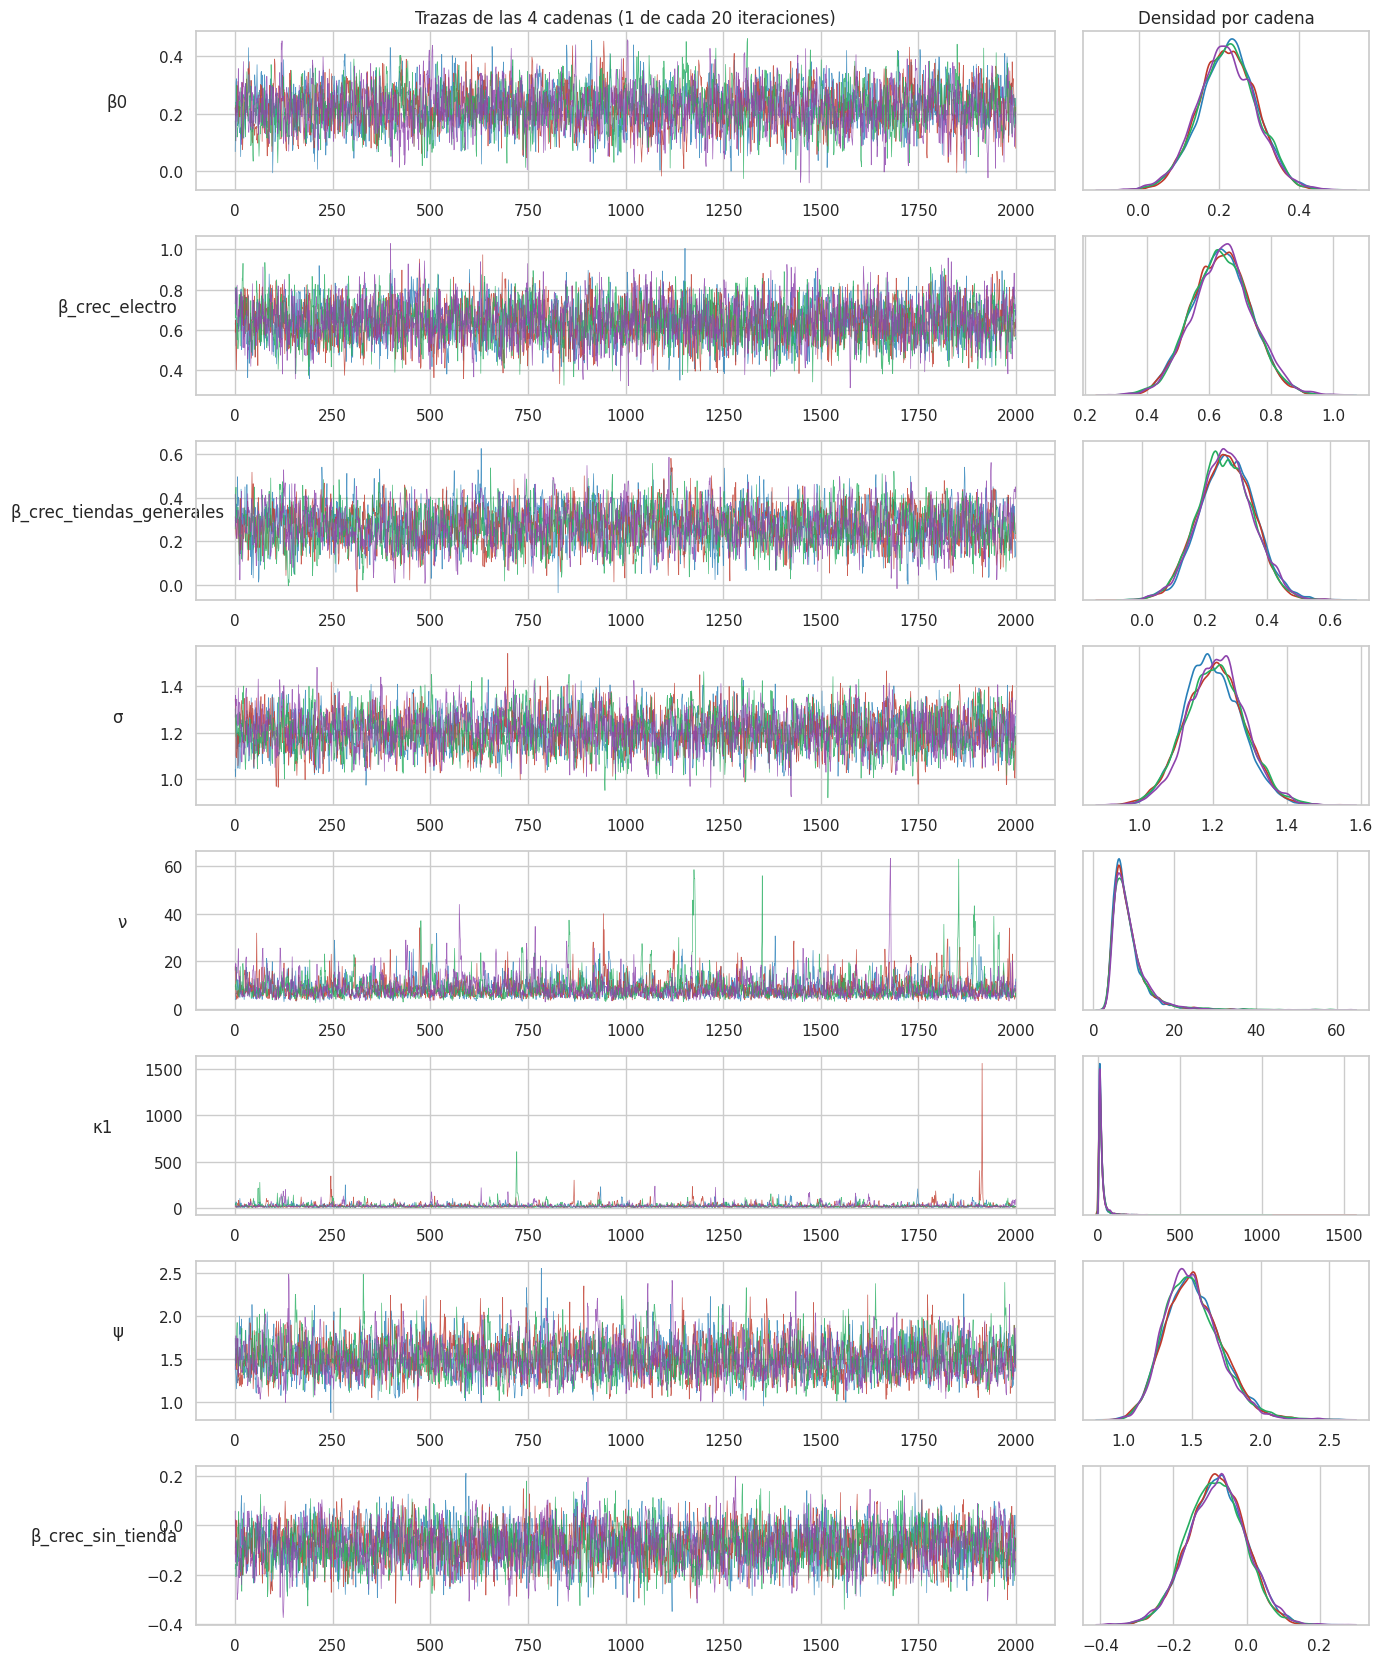

   [figura guardada] fig_D1_trazas.png


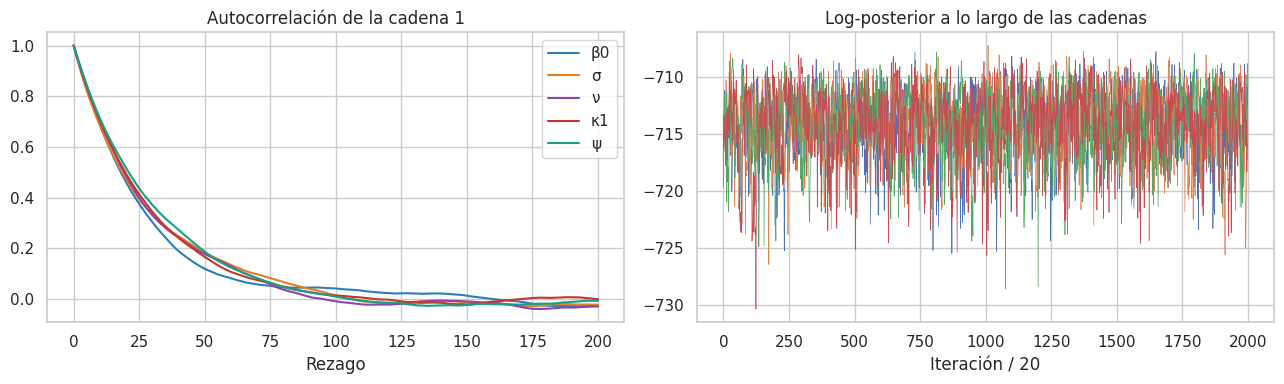

   [figura guardada] fig_D2_autocorrelacion_logpost.png


In [ ]:
titulo("7.3 Convergencia")


def r_hat_dividido(x):
    # R-hat dividiendo cada cadena en dos mitades (x: cadenas x iteraciones).
    n = x.shape[1] // 2
    p = np.concatenate([x[:, :n], x[:, n:2 * n]], axis=0)
    W = p.var(axis=1, ddof=1).mean()
    B = n * p.mean(axis=1).var(ddof=1)
    return float(np.sqrt(((n - 1) / n * W + B / n) / W))


def ess(x):
    # Tamaño efectivo de muestra con autocorrelaciones combinadas entre cadenas (Geyer, 1992).
    m, n = x.shape
    xc = x - x.mean(axis=1, keepdims=True)
    f = np.fft.rfft(xc, n=2 * n, axis=1)
    ac = np.fft.irfft(f * np.conj(f), axis=1)[:, :n] / n
    ac = ac / np.arange(n, 0, -1) * n               # autocovarianza insesgada
    W = x.var(axis=1, ddof=1).mean()
    var_plus = (n - 1) / n * W + x.mean(axis=1).var(ddof=1)
    rho = 1 - (W - ac.mean(axis=0)) / var_plus
    suma, t = 0.0, 1
    while t + 1 < n:
        par = rho[t] + rho[t + 1]
        if par < 0:
            break
        suma += par
        t += 2
    return float(m * n / (1 + 2 * suma))


tabla_conv = pd.DataFrame({
    "R_hat": [r_hat_dividido(cadenas[:, :, j]) for j in range(D)],
    "ESS": [ess(cadenas[:, :, j]) for j in range(D)],
}, index=NOMBRES)
tabla_conv["ESS_por_iteracion_%"] = 100 * tabla_conv["ESS"] / (N_CADENAS * N_ITER)
print(tabla_conv.round(3).to_string())
print(f"\nR-hat máximo: {tabla_conv['R_hat'].max():.3f} | ESS mínimo: {tabla_conv['ESS'].min():.0f}")
guardar_tabla(tabla_conv.round(3), "tabla_convergencia.csv")

transf = lambda j, v: np.exp(v) if (j in (K, K + 1) or j >= K + 2) else v     # σ, ν, κ y ψ en su escala original
a_graf = [0, 1, 4, K, K + 1, K + 2, D - 1, 2]
colores = ["#2980b9", "#c0392b", "#27ae60", "#8e44ad"]
fig, ax = plt.subplots(len(a_graf), 2, figsize=(14, 2.1 * len(a_graf)), gridspec_kw={"width_ratios": [3, 1]})
for fila, j in enumerate(a_graf):
    for c in range(N_CADENAS):
        v = transf(j, cadenas[c, :, j])
        ax[fila, 0].plot(v[::20], color=colores[c], lw=0.5, alpha=0.8)
        sns.kdeplot(v, ax=ax[fila, 1], color=colores[c], lw=1.2)
    ax[fila, 0].set_ylabel(NOMBRES[j], rotation=0, labelpad=30)
    ax[fila, 1].set_ylabel("")
    ax[fila, 1].set_yticks([])
ax[0, 0].set_title("Trazas de las 4 cadenas (1 de cada 20 iteraciones)")
ax[0, 1].set_title("Densidad por cadena")
guardar_figura("fig_D1_trazas.png")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lags = np.arange(0, 201)
for j, col in [(0, "#2980b9"), (K, "#e67e22"), (K + 1, "#8e44ad"), (K + 2, "#c0392b"), (D - 1, "#16a085")]:
    v = cadenas[0, :, j] - cadenas[0, :, j].mean()
    f = np.fft.rfft(v, n=2 * len(v))
    r_ = np.fft.irfft(f * np.conj(f))[:len(lags)]
    ax[0].plot(lags, r_ / r_[0], color=col, label=NOMBRES[j])
ax[0].set_title("Autocorrelación de la cadena 1"); ax[0].set_xlabel("Rezago"); ax[0].legend()
ax[1].plot(lps_c.T[::20], lw=0.5)
ax[1].set_title("Log-posterior a lo largo de las cadenas"); ax[1].set_xlabel("Iteración / 20")
guardar_figura("fig_D2_autocorrelacion_logpost.png")

### 7.4 Resumen de la posterior

La tabla da, para cada parámetro, la media, la desviación, la mediana y el intervalo creíble del 95%. Para los coeficientes se agrega la probabilidad posterior de que sean positivos, que responde directamente a la pregunta de si una categoría del comercio tiene un efecto positivo sobre las ventas de muebles. Los $\beta_j$ están en puntos de crecimiento por cada desviación estándar de la variable.


7.4 Resumen de la posterior
                               media  desv_std    2.5%  mediana    97.5%  P(parámetro > 0)  R_hat
β0                             0.222     0.072   0.080    0.222    0.361             0.999  1.002
β_crec_electro                 0.640     0.096   0.456    0.640    0.829             1.000  1.001
β_crec_sin_tienda             -0.082     0.078  -0.235   -0.081    0.069             0.147  1.001
β_crec_construccion            0.401     0.083   0.242    0.399    0.568             1.000  1.001
β_crec_tiendas_generales       0.268     0.087   0.098    0.267    0.437             0.999  1.002
β_crec_gasolineras            -0.176     0.078  -0.331   -0.176   -0.025             0.011  1.003
β_crec_ingreso_disponible      0.112     0.107  -0.091    0.111    0.327             0.856  1.001
β_razon_inv_ventas_rezago1    -0.001     0.081  -0.161   -0.000    0.157             0.499  1.001
β_crec_muebles_hogar_rezago1  -0.122     0.074  -0.273   -0.119    0.017             0.04

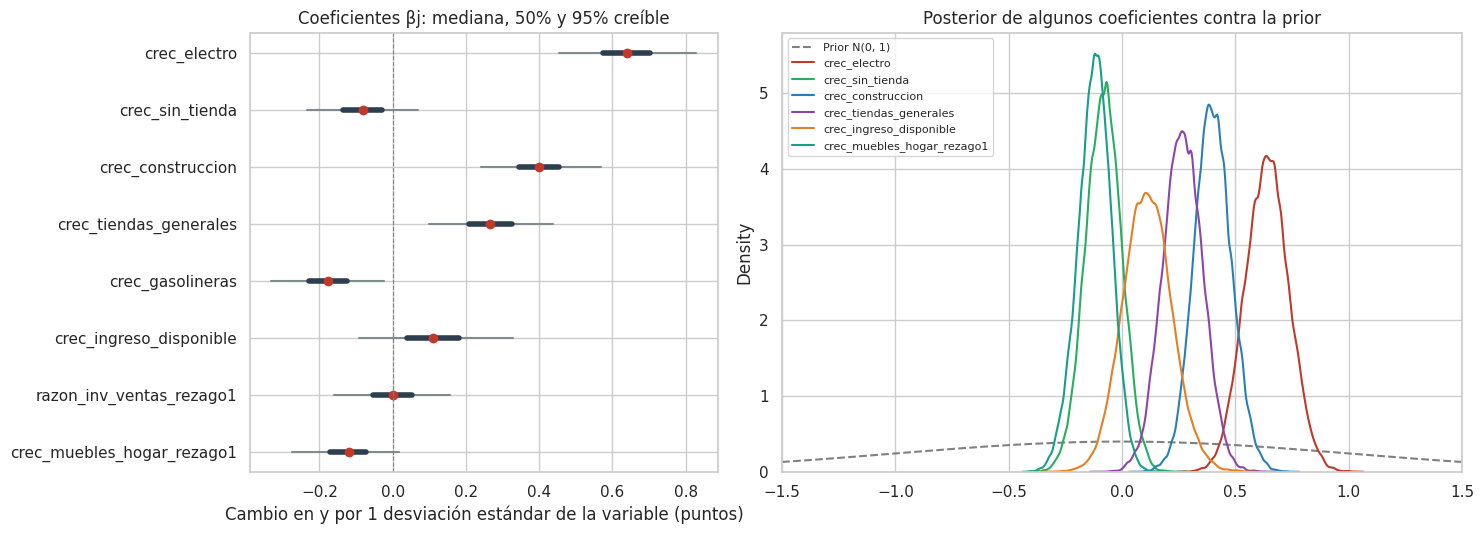

   [figura guardada] fig_D3_coeficientes.png


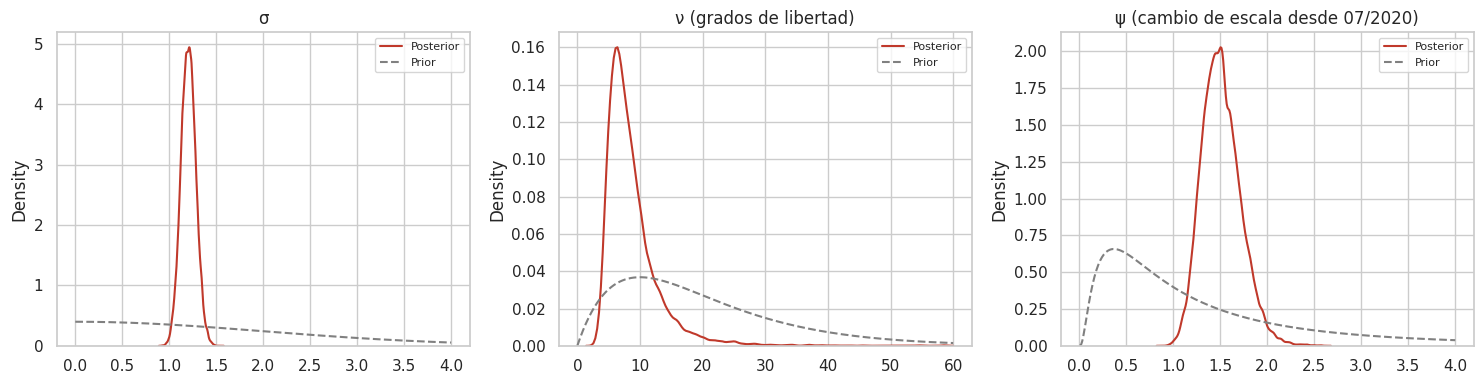

   [figura guardada] fig_D4_sigma_nu_psi.png

κ_m (factor que multiplica la escala en marzo, abril, mayo y junio de 2020):
       marzo  abril   mayo  junio
0.025    4.9   11.9   10.2    6.3
0.500   14.9   35.2   30.2   18.6
0.975   80.5  161.7  141.9   91.2
P(ψ > 1) = 0.999


In [ ]:
titulo("7.4 Resumen de la posterior")

muestras = cadenas.reshape(-1, D)                 # todas las cadenas juntas
post_esc = muestras.copy()
post_esc[:, K:] = np.exp(post_esc[:, K:])         # σ, ν, κ y ψ vuelven a su escala original

res_post = pd.DataFrame({
    "media": post_esc.mean(0), "desv_std": post_esc.std(0),
    "2.5%": np.quantile(post_esc, 0.025, axis=0), "mediana": np.median(post_esc, axis=0),
    "97.5%": np.quantile(post_esc, 0.975, axis=0),
}, index=NOMBRES)
res_post["P(parámetro > 0)"] = [float(np.mean(post_esc[:, j] > 0)) if j < K else np.nan for j in range(D)]
res_post["R_hat"] = tabla_conv["R_hat"]
print(res_post.round(3).to_string())
guardar_tabla(res_post.round(3), "tabla_posterior.csv")

# Intervalos creíbles de los coeficientes y comparación entre la prior y la posterior
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1.6]})
ordenj = list(range(1, K))[::-1]
for k, j in enumerate(ordenj):
    lo, q1, md, q3, hi = np.quantile(post_esc[:, j], [0.025, 0.25, 0.5, 0.75, 0.975])
    ax[0].plot([lo, hi], [k, k], color="#7f8c8d", lw=1.5)
    ax[0].plot([q1, q3], [k, k], color="#2c3e50", lw=4)
    ax[0].plot(md, k, "o", color="#c0392b")
ax[0].axvline(0, color="gray", ls="--", lw=0.8)
ax[0].set_yticks(range(len(ordenj))); ax[0].set_yticklabels([NOMBRES[j].replace("β_", "") for j in ordenj])
ax[0].set_title("Coeficientes βj: mediana, 50% y 95% creíble")
ax[0].set_xlabel("Cambio en y por 1 desviación estándar de la variable (puntos)")

g = np.linspace(-1.5, 1.5, 400)
ax[1].plot(g, PRIORS["beta"].pdf(g), color="gray", ls="--", label="Prior N(0, 1)")
for j, col in [(1, "#c0392b"), (2, "#27ae60"), (3, "#2980b9"), (4, "#8e44ad"), (6, "#e67e22"), (8, "#16a085")]:
    sns.kdeplot(post_esc[:, j], ax=ax[1], color=col, label=NOMBRES[j].replace("β_", ""))
ax[1].set_xlim(-1.5, 1.5)
ax[1].set_title("Posterior de algunos coeficientes contra la prior"); ax[1].legend(fontsize=8)
guardar_figura("fig_D3_coeficientes.png")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (j, ttl, prior_pdf, rango) in zip(ax, [
        (K, "σ", lambda x: PRIORS["sigma"].pdf(x), (0, 4)),
        (K + 1, "ν (grados de libertad)", lambda x: PRIORS["nu"].pdf(x), (0, 60)),
        (D - 1, "ψ (cambio de escala desde 07/2020)", lambda x: PRIORS["log_psi"].pdf(np.log(np.maximum(x, 1e-9))) / np.maximum(x, 1e-9), (0, 4))]):
    gg = np.linspace(max(rango[0], 1e-3), rango[1], 400)
    sns.kdeplot(post_esc[:, j], ax=a, color="#c0392b", label="Posterior", clip=rango)
    a.plot(gg, prior_pdf(gg), color="gray", ls="--", label="Prior")
    a.set_title(ttl); a.legend(fontsize=8)
guardar_figura("fig_D4_sigma_nu_psi.png")

kap = post_esc[:, K + 2:K + 2 + M]
print("\nκ_m (factor que multiplica la escala en marzo, abril, mayo y junio de 2020):")
print(pd.DataFrame(kap, columns=["marzo", "abril", "mayo", "junio"]).quantile([0.025, 0.5, 0.975]).round(1).to_string())
print(f"P(ψ > 1) = {np.mean(post_esc[:, D - 1] > 1):.3f}")

### 7.5 Chequeo predictivo a posteriori

Se simulan conjuntos de datos desde el modelo ya ajustado y se comparan con los observados. Si el modelo es adecuado, los datos reales deben parecer una réplica más. Se revisa la cobertura de los intervalos predictivos y cinco estadísticos de prueba, entre ellos la curtosis y el cociente de desviaciones antes y después de julio de 2020, que son justo las características que motivaron la t de Student y el factor $\psi$.


7.5 Chequeo predictivo a posteriori (entrenamiento)
 nivel_nominal  cobertura_meses_normales  cobertura_meses_COVID
          0.50                     0.509                    0.0
          0.80                     0.816                    1.0
          0.90                     0.912                    1.0
          0.95                     0.938                    1.0
   [tabla guardada] tabla_cobertura_entrenamiento.csv


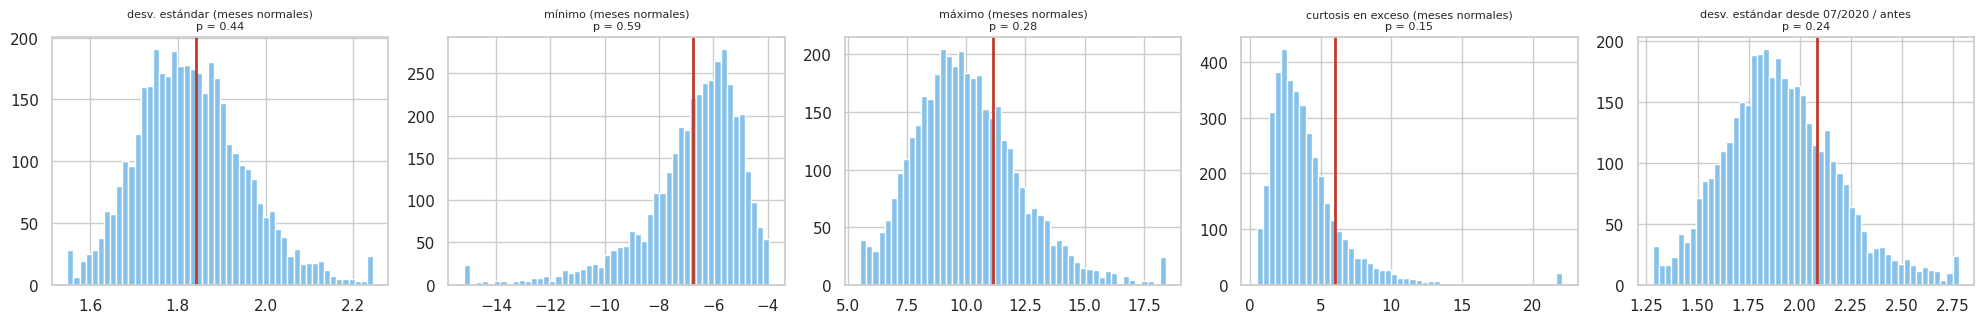

   [figura guardada] fig_D5_chequeo_predictivo_posteriori.png
                         estadístico  observado  mediana_réplicas  p_posterior
     desv. estándar (meses normales)      1.841             1.822        0.442
             mínimo (meses normales)     -6.741            -6.388        0.589
             máximo (meses normales)     11.150             9.839        0.281
 curtosis en exceso (meses normales)      6.033             3.336        0.153
desv. estándar desde 07/2020 / antes      2.083             1.886        0.244
   [tabla guardada] tabla_chequeo_predictivo_posteriori.csv


In [ ]:
titulo("7.5 Chequeo predictivo a posteriori (entrenamiento)")

rng_pp = np.random.default_rng(SEMILLA + 100)
N_PP = 4000
sel = rng_pp.choice(len(post_esc), N_PP, replace=False)
dr = post_esc[sel]


def predictiva(dr_, Zm, post_flag, idx_cov, r):
    # Simula y desde la posterior: media, escala por mes y error t de Student, para cada extracción.
    mu = dr_[:, :K] @ Zm.T
    esc = dr_[:, [K]] * (dr_[:, [D - 1]] ** post_flag[None, :])
    if idx_cov is not None and len(idx_cov):
        esc = esc.copy()
        esc[:, idx_cov] *= dr_[:, K + 2:K + 2 + M]
    yrep = mu + r.standard_t(dr_[:, [K + 1]], size=mu.shape) * esc
    return mu, esc, yrep


mu_tr, esc_tr, yrep_tr = predictiva(dr, Z, post, idx_covid, rng_pp)

# Cobertura de los intervalos predictivos en los meses de entrenamiento
cob = []
for nivel in (0.5, 0.8, 0.9, 0.95):
    lo, hi = np.quantile(yrep_tr, [(1 - nivel) / 2, 1 - (1 - nivel) / 2], axis=0)
    dentro = (y >= lo) & (y <= hi)
    cob.append({"nivel_nominal": nivel, "cobertura_meses_normales": dentro[mask_normal].mean(),
                "cobertura_meses_COVID": dentro[~mask_normal].mean()})
cob = pd.DataFrame(cob).round(3)
print(cob.to_string(index=False))
guardar_tabla(cob, "tabla_cobertura_entrenamiento.csv", indice=False)

# Estadísticos de prueba: la muestra observada contra las réplicas
est = {
    "desv. estándar (meses normales)": lambda v: v[:, mask_normal].std(axis=1),
    "mínimo (meses normales)": lambda v: v[:, mask_normal].min(axis=1),
    "máximo (meses normales)": lambda v: v[:, mask_normal].max(axis=1),
    "curtosis en exceso (meses normales)": lambda v: stats.kurtosis(v[:, mask_normal], axis=1),
    "desv. estándar desde 07/2020 / antes": lambda v: v[:, post == 1].std(axis=1) / v[:, (post == 0) & mask_normal].std(axis=1),
}
filas, fig, ax = [], *plt.subplots(1, len(est), figsize=(4 * len(est), 3.4))
for a, (nom, f) in zip(ax, est.items()):
    rep, obs = f(yrep_tr), f(y[None, :])[0]
    p = float(np.mean(rep >= obs))
    filas.append({"estadístico": nom, "observado": round(float(obs), 3), "mediana_réplicas": round(float(np.median(rep)), 3),
                  "p_posterior": round(p, 3)})
    a.hist(np.clip(rep, *np.quantile(rep, [0.005, 0.995])), bins=50, color="#85c1e9")
    a.axvline(obs, color="#c0392b", lw=2)
    a.set_title(f"{nom}\np = {p:.2f}", fontsize=8)
guardar_figura("fig_D5_chequeo_predictivo_posteriori.png")
ppc = pd.DataFrame(filas)
print(ppc.to_string(index=False))
guardar_tabla(ppc, "tabla_chequeo_predictivo_posteriori.csv", indice=False)

# Parte E. Validación con los 24 meses reservados
(Numeral 9 del PDF. Se califica en Estadística Bayesiana.)

Los 24 meses de prueba (agosto de 2024 a julio de 2026) no se usaron en nada hasta aquí: ni en el EDA, ni en la estandarización, ni en el ajuste. Se predice cada mes con la posterior calculada con el entrenamiento. Como el modelo usa variables del mismo mes, la prueba mide qué tan bien se explica el crecimiento *una vez se conocen* las demás categorías, y no un pronóstico con meses de anticipación.

### 8.1 Predicción mes a mes


8.1 Predicción de los 24 meses de prueba
  fecha  y_real  y_predicho  lo_90  hi_90  lo_50  hi_50  log_dens_predictiva  dentro_90
2024-08   -0.48       -0.63  -4.03   2.92  -1.86   0.71                -1.54       True
2024-09    2.51       -0.38  -3.94   3.11  -1.62   0.98                -2.79       True
2024-10   -1.13        0.88  -2.49   4.35  -0.36   2.20                -2.21       True
2024-11    1.89        0.36  -2.95   3.80  -0.96   1.61                -1.95       True
2024-12    4.97       -0.28  -3.68   3.25  -1.61   1.02                -4.68      False
2025-01   -3.35       -0.81  -4.20   2.54  -2.11   0.43                -2.54       True
2025-02    0.29        0.36  -3.10   3.74  -0.95   1.68                -1.55       True
2025-03   -1.65        1.06  -2.40   4.58  -0.21   2.42                -2.66       True
2025-04    1.05        0.26  -3.10   3.73  -0.97   1.54                -1.66       True
2025-05   -2.14       -0.53  -3.98   2.88  -1.80   0.74                -1.98  

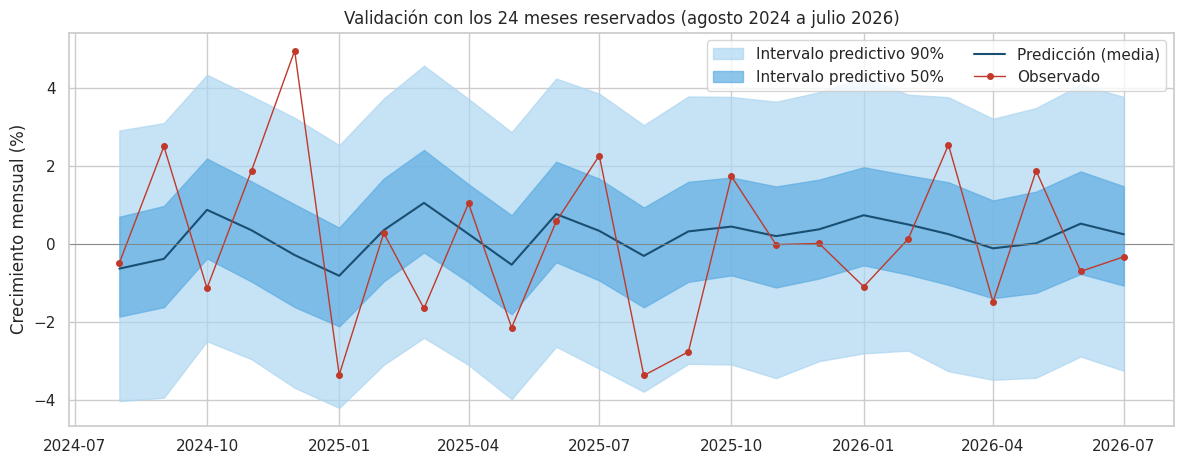

   [figura guardada] fig_E1_validacion_prueba.png


In [ ]:
titulo("8.1 Predicción de los 24 meses de prueba")

# Las variables de la base de prueba se estandarizan con la media y la desviación de los meses normales
# del ENTRENAMIENTO, igual que en el ajuste, para no filtrar información de la prueba.
Zt = np.column_stack([np.ones(len(prueba)), ((prueba[X] - media_x) / desv_x).values])
yt = prueba[Y].values
post_t = np.ones(len(prueba))                        # todos los meses de prueba son posteriores a 07/2020
nivel_prev = pd.concat([entren["nivel_muebles_hogar"].iloc[[-1]], prueba["nivel_muebles_hogar"].iloc[:-1]]).values
nivel_real = prueba["nivel_muebles_hogar"].values

rng_t = np.random.default_rng(SEMILLA + 200)
mu_t, esc_t, yrep_t = predictiva(dr, Zt, post_t, None, rng_t)
pred_media = mu_t.mean(0)

# Densidad predictiva exacta de cada observación (promedio de la densidad t sobre las extracciones)
dens = stats.t.pdf(yt[None, :], dr[:, [K + 1]], loc=mu_t, scale=esc_t)
lpd = np.log(dens.mean(0))

tabla_t = pd.DataFrame({
    "fecha": prueba["fecha"].dt.strftime("%Y-%m"), "y_real": yt, "y_predicho": pred_media,
    "lo_90": np.quantile(yrep_t, 0.05, axis=0), "hi_90": np.quantile(yrep_t, 0.95, axis=0),
    "lo_50": np.quantile(yrep_t, 0.25, axis=0), "hi_50": np.quantile(yrep_t, 0.75, axis=0),
    "log_dens_predictiva": lpd,
})
tabla_t["dentro_90"] = (tabla_t["y_real"] >= tabla_t["lo_90"]) & (tabla_t["y_real"] <= tabla_t["hi_90"])
print(tabla_t.round(2).to_string(index=False))
guardar_tabla(tabla_t.round(3), "tabla_prueba_mes_a_mes.csv", indice=False)

fig, ax = plt.subplots(figsize=(12, 4.8))
f = prueba["fecha"]
ax.fill_between(f, tabla_t["lo_90"], tabla_t["hi_90"], color="#aed6f1", alpha=0.7, label="Intervalo predictivo 90%")
ax.fill_between(f, tabla_t["lo_50"], tabla_t["hi_50"], color="#5dade2", alpha=0.7, label="Intervalo predictivo 50%")
ax.plot(f, tabla_t["y_predicho"], color="#1b4f72", lw=1.5, label="Predicción (media)")
ax.plot(f, yt, "o-", color="#c0392b", ms=4, lw=1, label="Observado")
ax.axhline(0, color="gray", lw=0.6)
ax.set_ylabel("Crecimiento mensual (%)")
ax.set_title("Validación con los 24 meses reservados (agosto 2024 a julio 2026)")
ax.legend(ncol=2)
guardar_figura("fig_E1_validacion_prueba.png")

### 8.2 Métricas y comparación con alternativas simples

Se reportan el error cuadrático medio (RMSE), el error absoluto medio (MAE), el CRPS, que evalúa la distribución predictiva completa y no solo su centro, y la densidad predictiva logarítmica. Se comparan con tres alternativas que no usan las variables explicativas: la media histórica, la persistencia (repetir el crecimiento del mes anterior) y una t de Student ajustada solo a la historia de $y$ desde julio de 2020. Si el modelo no mejora a estas alternativas, hay que decirlo.

In [ ]:
titulo("8.2 Métricas y comparación con alternativas simples")

# Alternativas sin variables explicativas, para ver si el modelo aporta algo:
#  (a) media histórica de los meses normales del entrenamiento como predicción puntual,
#  (b) persistencia: el crecimiento del mes anterior,
#  (c) una t de Student ajustada por máxima verosimilitud al crecimiento desde 07/2020 (solo historia de Y).
y_desde = entren.loc[entren["fecha"] >= "2020-07-01", Y].values
nu_b, loc_b, esc_b = stats.t.fit(y_desde)
pred_media_hist = np.full(len(yt), normales[Y].mean())
pred_persist = prueba["crec_muebles_hogar_rezago1"].values


def crps_muestras(muestras, obs):
    # CRPS estimado con muestras: E|Y - y| - 0.5 E|Y - Y'|  (menor es mejor)
    s = np.sort(muestras, axis=0)
    n = s.shape[0]
    t1 = np.abs(s - obs[None, :]).mean(0)
    pesos = (2 * np.arange(1, n + 1) - n - 1)[:, None]
    t2 = (pesos * s).sum(0) / n ** 2
    return t1 - t2


rng_b = np.random.default_rng(SEMILLA + 300)
y_b = stats.t.rvs(nu_b, loc_b, esc_b, size=(N_PP, len(yt)), random_state=rng_b)
lpd_b = stats.t.logpdf(yt, nu_b, loc_b, esc_b)

filas = []
for nombre, pt, crps, lp_, an90, cob90 in [
    ("Modelo bayesiano (t robusta)", pred_media, crps_muestras(yrep_t, yt).mean(), lpd.mean(),
     np.mean(tabla_t["hi_90"] - tabla_t["lo_90"]), tabla_t["dentro_90"].mean()),
    ("t de Student solo con la historia de Y", np.full(len(yt), loc_b), crps_muestras(y_b, yt).mean(), lpd_b.mean(),
     np.mean(np.quantile(y_b, 0.95, axis=0) - np.quantile(y_b, 0.05, axis=0)),
     np.mean((yt >= np.quantile(y_b, 0.05, axis=0)) & (yt <= np.quantile(y_b, 0.95, axis=0)))),
    ("Media histórica (meses normales)", pred_media_hist, np.nan, np.nan, np.nan, np.nan),
    ("Persistencia (mes anterior)", pred_persist, np.nan, np.nan, np.nan, np.nan),
]:
    filas.append({"método": nombre, "RMSE": np.sqrt(np.mean((yt - pt) ** 2)), "MAE": np.mean(np.abs(yt - pt)),
                  "CRPS": crps, "log_dens_predictiva_media": lp_, "ancho_medio_int90": an90, "cobertura_90": cob90})
metricas = pd.DataFrame(filas)
print(metricas.round(3).to_string(index=False))
guardar_tabla(metricas.round(3), "tabla_metricas_prueba.csv", indice=False)

cob_t = []
for nivel in (0.5, 0.8, 0.9, 0.95):
    lo, hi = np.quantile(yrep_t, [(1 - nivel) / 2, 1 - (1 - nivel) / 2], axis=0)
    cob_t.append({"nivel_nominal": nivel, "cobertura_observada": float(np.mean((yt >= lo) & (yt <= hi)))})
cob_t = pd.DataFrame(cob_t).round(3)
print("\nCobertura de los intervalos predictivos en la prueba (24 meses):")
print(cob_t.to_string(index=False))
guardar_tabla(cob_t, "tabla_cobertura_prueba.csv", indice=False)

# Mejora del modelo sobre la t solo con la historia de Y, y su incertidumbre (24 meses: se reporta sin exagerar)
r2_t = 1 - np.sum((yt - pred_media) ** 2) / np.sum((yt - yt.mean()) ** 2)
print(f"\nR² fuera de muestra (prueba) de la predicción media: {r2_t:.3f}")
print(f"Corrector por mes: log densidad predictiva media = {lpd.mean():.3f} (modelo) contra {lpd_b.mean():.3f} (solo historia de Y)")
print(f"PIT: proporción de observaciones por encima de la mediana predictiva = {np.mean(yt > np.median(yrep_t, axis=0)):.2f}")
print(f"Correlación entre la predicción media y lo observado en la prueba: {np.corrcoef(pred_media, yt)[0, 1]:.3f}")


8.2 Métricas y comparación con alternativas simples
                                método  RMSE   MAE  CRPS  log_dens_predictiva_media  ancho_medio_int90  cobertura_90
          Modelo bayesiano (t robusta) 2.039 1.635 1.153                     -2.147              6.898         0.958
t de Student solo con la historia de Y 2.040 1.621 1.168                     -2.202              9.521         0.958
      Media histórica (meses normales) 2.021 1.626   NaN                        NaN                NaN           NaN
           Persistencia (mes anterior) 3.275 2.776   NaN                        NaN                NaN           NaN
   [tabla guardada] tabla_metricas_prueba.csv

Cobertura de los intervalos predictivos en la prueba (24 meses):
 nivel_nominal  cobertura_observada
          0.50                0.375
          0.80                0.792
          0.90                0.958
          0.95                0.958
   [tabla guardada] tabla_cobertura_prueba.csv

R² fuera de muestra (p

# Parte F. Interpretación y rango de referencia para el inventario
(Numeral 10 del PDF. Se califica en Pensamiento Crítico y en Estadística Bayesiana.)

### 9.1 Cuánto de la variación se asocia con las variables

In [ ]:
titulo("9.1 Cuánto de la variación se asocia con las variables")

# R² bayesiano: para cada extracción, varianza de la parte explicada contra la varianza total de y
# (parte explicada + residuo observado). Se calcula en los meses normales del entrenamiento, donde
# los episodios extremos no dominan la varianza, y en los 24 meses de prueba.
Zn, yn = Z[mask_normal], y[mask_normal]
mu_n = dr[:, :K] @ Zn.T
r2_ent = np.var(mu_n, axis=1) / (np.var(mu_n, axis=1) + np.var(yn[None, :] - mu_n, axis=1))
r2_pru = np.var(mu_t, axis=1) / (np.var(mu_t, axis=1) + np.var(yt[None, :] - mu_t, axis=1))
resumen_r2 = pd.DataFrame({
    "muestra": ["Entrenamiento (meses normales)", "Prueba (24 meses)"],
    "R2_mediana": [np.median(r2_ent), np.median(r2_pru)],
    "R2_2.5%": [np.quantile(r2_ent, 0.025), np.quantile(r2_pru, 0.025)],
    "R2_97.5%": [np.quantile(r2_ent, 0.975), np.quantile(r2_pru, 0.975)],
}).round(3)
print(resumen_r2.to_string(index=False))
guardar_tabla(resumen_r2, "tabla_r2_bayesiano.csv", indice=False)

# Aporte de cada variable: desviación estándar de βj·zj en los meses normales (cuánto mueve cada una a y)
aporte = pd.DataFrame({
    "variable": X,
    "aporte_mediano (desv. de βj·zj)": [np.median(np.abs(dr[:, j + 1]) * Zn[:, j + 1].std()) for j in range(len(X))],
    "P(βj > 0)": [np.mean(dr[:, j + 1] > 0) for j in range(len(X))],
    "int_95%_excluye_0": [bool(np.quantile(dr[:, j + 1], 0.025) > 0 or np.quantile(dr[:, j + 1], 0.975) < 0) for j in range(len(X))],
}).round(3).sort_values("aporte_mediano (desv. de βj·zj)", ascending=False)
print("\n" + aporte.to_string(index=False))
guardar_tabla(aporte, "tabla_aporte_variables.csv", indice=False)

print(f"\nDesviación del error en meses normales antes de 07/2020 (σ·sqrt(ν/(ν-2)), mediana): "
      f"{np.median(dr[:, K] * np.sqrt(dr[:, K + 1] / (dr[:, K + 1] - 2))):.2f} puntos | "
      f"desde 07/2020 (× ψ): {np.median(dr[:, K] * dr[:, D - 1] * np.sqrt(dr[:, K + 1] / (dr[:, K + 1] - 2))):.2f} puntos")


9.1 Cuánto de la variación se asocia con las variables
                       muestra  R2_mediana  R2_2.5%  R2_97.5%
Entrenamiento (meses normales)       0.310    0.227     0.384
             Prueba (24 meses)       0.054    0.034     0.083
   [tabla guardada] tabla_r2_bayesiano.csv

                  variable  aporte_mediano (desv. de βj·zj)  P(βj > 0)  int_95%_excluye_0
              crec_electro                            0.660      1.000               True
         crec_construccion                            0.399      1.000               True
    crec_tiendas_generales                            0.271      1.000               True
          crec_gasolineras                            0.176      0.012               True
crec_muebles_hogar_rezago1                            0.161      0.045              False
   crec_ingreso_disponible                            0.114      0.858              False
           crec_sin_tienda                            0.085      0.142              

### 9.2 Del crecimiento a las ventas: rango de referencia

El crecimiento mensual $g$ se convierte en ventas con $V_t = V_{t-1}\, e^{g/100}$, donde $V_{t-1}$ son las ventas del mes anterior en millones de dólares. Se hace de dos formas. Primero, con los 24 meses de prueba, para ver si el intervalo creíble en dólares contiene las ventas observadas. Segundo, para el mes siguiente al último dato (agosto de 2026), cuando todavía no se conocen las variables explicativas. Ahí se deja variar su valor entre los observados desde julio de 2020, de modo que el rango incluye la incertidumbre de no conocerlas. Este segundo rango es el que se propone como referencia para el análisis de inventario.


9.2 Rango de referencia para el inventario
  fecha  ventas_reales_MM  ventas_esperadas_MM  lo_90_MM  hi_90_MM  dentro_90
2024-08           10339.0              10329.0    9979.0   10697.0       True
2024-09           10602.0              10303.0    9940.0   10665.0       True
2024-10           10483.0              10701.0   10341.0   11073.0       True
2024-11           10683.0              10518.0   10178.0   10889.0       True
2024-12           11227.0              10660.0   10297.0   11035.0      False
2025-01           10857.0              11135.0   10765.0   11516.0       True
...
Cobertura del intervalo del 90% en dólares: 0.958 | ancho medio: 732 millones (6.9% del nivel)
   [tabla guardada] tabla_ventas_nivel_prueba.csv

Último nivel observado (julio de 2026): 10,537 millones de dólares
percentil  crecimiento_%  ventas_MM  diferencia_con_la_mediana_MM
       5%          -3.90   10134.07                       -407.84
      25%          -1.44   10386.34                       -15

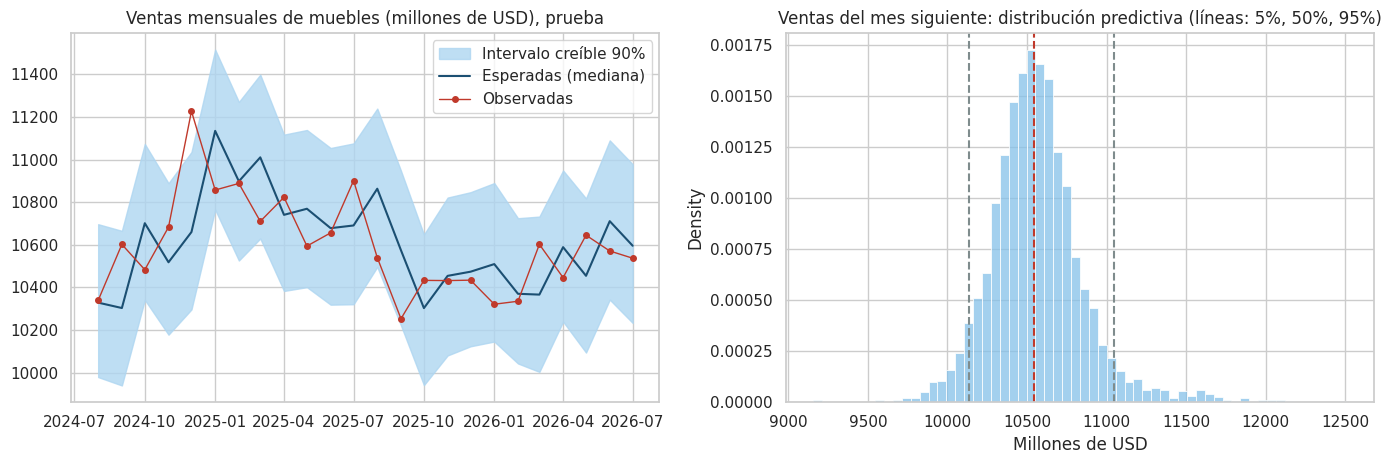

   [figura guardada] fig_F1_rango_inventario.png


In [ ]:
titulo("9.2 Rango de referencia para el inventario")

# (a) Validación en dólares: con las ventas del mes anterior y el crecimiento predicho se obtiene
# el nivel de ventas esperado del mes, y su intervalo creíble se compara con el nivel real.
niv_pred = nivel_prev[None, :] * np.exp(yrep_t / 100)
tabla_n = pd.DataFrame({
    "fecha": prueba["fecha"].dt.strftime("%Y-%m"), "ventas_reales_MM": nivel_real,
    "ventas_esperadas_MM": np.median(niv_pred, axis=0),
    "lo_90_MM": np.quantile(niv_pred, 0.05, axis=0), "hi_90_MM": np.quantile(niv_pred, 0.95, axis=0),
})
tabla_n["dentro_90"] = (tabla_n["ventas_reales_MM"] >= tabla_n["lo_90_MM"]) & (tabla_n["ventas_reales_MM"] <= tabla_n["hi_90_MM"])
ancho_pct = 100 * (tabla_n["hi_90_MM"] - tabla_n["lo_90_MM"]) / nivel_real
print(tabla_n.round(0).astype({"dentro_90": bool}).head(6).to_string(index=False))
print(f"...\nCobertura del intervalo del 90% en dólares: {tabla_n['dentro_90'].mean():.3f} | "
      f"ancho medio: {np.mean(tabla_n['hi_90_MM'] - tabla_n['lo_90_MM']):.0f} millones ({ancho_pct.mean():.1f}% del nivel)")
guardar_tabla(tabla_n.round(1), "tabla_ventas_nivel_prueba.csv", indice=False)

# (b) Rango de referencia para el mes siguiente a la base (agosto de 2026). No conocemos todavía las
# variables explicativas de ese mes, así que se hace variar su valor entre los observados desde 07/2020
# (entrenamiento y prueba). El resultado incluye la incertidumbre de no conocerlas.
hist_post = pd.concat([entren[entren["fecha"] >= "2020-07-01"], prueba])
Z_hist = np.column_stack([np.ones(len(hist_post)), ((hist_post[X] - media_x) / desv_x).values])
rng_f = np.random.default_rng(SEMILLA + 400)
filas_z = rng_f.integers(0, len(Z_hist), N_PP)
mu_f = np.einsum("ij,ij->i", dr[:, :K], Z_hist[filas_z])
esc_f = dr[:, K] * dr[:, D - 1]
y_f = mu_f + rng_f.standard_t(dr[:, K + 1]) * esc_f
ult_nivel = float(prueba["nivel_muebles_hogar"].iloc[-1])
niv_f = ult_nivel * np.exp(y_f / 100)
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
ref = pd.DataFrame({"percentil": [f"{int(q * 100)}%" for q in qs],
                    "crecimiento_%": np.quantile(y_f, qs),
                    "ventas_MM": np.quantile(niv_f, qs)})
ref["diferencia_con_la_mediana_MM"] = ref["ventas_MM"] - np.median(niv_f)
print(f"\nÚltimo nivel observado (julio de 2026): {ult_nivel:,.0f} millones de dólares")
print(ref.round(2).to_string(index=False))
guardar_tabla(ref.round(2), "tabla_rango_referencia_inventario.csv", indice=False)
print(f"\nProbabilidad de que el mes siguiente crezca menos de -2%: {np.mean(y_f < -2):.3f} | más de 2%: {np.mean(y_f > 2):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
f = prueba["fecha"]
ax[0].fill_between(f, tabla_n["lo_90_MM"], tabla_n["hi_90_MM"], color="#aed6f1", alpha=0.8, label="Intervalo creíble 90%")
ax[0].plot(f, tabla_n["ventas_esperadas_MM"], color="#1b4f72", label="Esperadas (mediana)")
ax[0].plot(f, nivel_real, "o-", color="#c0392b", ms=4, lw=1, label="Observadas")
ax[0].set_title("Ventas mensuales de muebles (millones de USD), prueba"); ax[0].legend()
sns.histplot(niv_f, bins=60, color="#85c1e9", ax=ax[1], stat="density")
for q, c in zip([0.05, 0.5, 0.95], ["#7f8c8d", "#c0392b", "#7f8c8d"]):
    ax[1].axvline(np.quantile(niv_f, q), color=c, ls="--")
ax[1].set_title("Ventas del mes siguiente: distribución predictiva (líneas: 5%, 50%, 95%)")
ax[1].set_xlabel("Millones de USD")
guardar_figura("fig_F1_rango_inventario.png")

# Parte G. Cierre de la entrega final

### 10. Resumen y archivos de salida

Esta última celda imprime el resumen, guarda un archivo de texto con las muestras de la posterior y comprime todas las tablas y figuras en un `.zip`. Si se está corriendo en Colab, el zip se descarga solo.

In [ ]:
titulo("10. Resumen y archivos de salida")

lineas = [
    "Modelo: y_t = b0 + suma_j b_j z_jt + e_t, con e_t ~ t_nu(0, sigma_t) y sigma_t = sigma * lambda_t * psi^I(t >= 2020-07).",
    f"Metropolis-Hastings: {N_CADENAS} cadenas, {N_BURN} de calentamiento y {N_ITER} iteraciones cada una; aceptación entre {min(tasas):.2f} y {max(tasas):.2f}.",
    f"Convergencia: R-hat máximo {tabla_conv['R_hat'].max():.3f}, ESS mínimo {tabla_conv['ESS'].min():.0f}.",
    "Coeficientes con intervalo creíble del 95% que excluye 0: " + ", ".join(
        f"{X[j]} ({'+' if np.median(dr[:, j + 1]) > 0 else '-'})" for j in range(len(X))
        if (np.quantile(dr[:, j + 1], 0.025) > 0 or np.quantile(dr[:, j + 1], 0.975) < 0)) + ".",
    f"R2 bayesiano (meses normales, entrenamiento): {np.median(r2_ent):.2f}; en la prueba: {np.median(r2_pru):.2f}.",
    f"Prueba (24 meses): RMSE {metricas.iloc[0]['RMSE']:.2f}, cobertura del intervalo 90% = {tabla_t['dentro_90'].mean():.2f}.",
    f"Rango de referencia del mes siguiente (90%): {ref.iloc[0]['ventas_MM']:,.0f} a {ref.iloc[-1]['ventas_MM']:,.0f} millones de USD.",
]
for l in lineas:
    print("- " + l)
(CARPETA_TABLAS / "resumen_final.txt").write_text("\n".join(lineas), encoding="utf-8")

# Exportar fragmentos LaTeX para el informe Overleaf
try:
    coef = res_post.loc[X].round(3) if "res_post" in dir() else None
except Exception:
    coef = None
lines_tex = ["% Generado automáticamente — no editar a mano"]
lines_tex.append(f"% R-hat max {tabla_conv['R_hat'].max():.4f}, ESS min {tabla_conv['ESS'].min():.0f}")
lines_tex.append(f"% RMSE prueba {metricas.iloc[0]['RMSE']:.3f}, cobertura 90% {tabla_t['dentro_90'].mean():.2f}")
(CARPETA_TABLAS / "metricas_informe.tex").write_text("\n".join(lines_tex), encoding="utf-8")
print("   [latex] metricas_informe.tex")

np.save(CARPETA_TABLAS / "posterior_muestras.npy", post_esc.astype(np.float32))

print("\nArchivos generados:")
for f in sorted(CARPETA_SALIDAS.iterdir()):
    print("  ", f.name)

import zipfile
zip_path = Path.cwd() / "salidas_entrega_final.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for carpeta in (CARPETA_SALIDAS, CARPETA_TABLAS):
        for f in carpeta.iterdir():
            if f.is_file():
                zf.write(f, arcname=f"{carpeta.name}/{f.name}")
ruta_zip = str(zip_path)
print("\nZip creado:", ruta_zip)
try:
    from google.colab import files
    files.download(ruta_zip)
except ImportError:
    print("(No se está corriendo en Colab, el zip queda en la carpeta de trabajo.)")


10. Resumen y archivos de salida
- Modelo: y_t = b0 + suma_j b_j z_jt + e_t, con e_t ~ t_nu(0, sigma_t) y sigma_t = sigma * lambda_t * psi^I(t >= 2020-07).
- Metropolis-Hastings: 4 cadenas, 30000 de calentamiento y 40000 iteraciones cada una; aceptación entre 0.16 y 0.21.
- Convergencia: R-hat máximo 1.004, ESS mínimo 2063.
- Coeficientes con intervalo creíble del 95% que excluye 0: crec_electro (+), crec_construccion (+), crec_tiendas_generales (+), crec_gasolineras (-).
- R2 bayesiano (meses normales, entrenamiento): 0.31; en la prueba: 0.05.
- Prueba (24 meses): RMSE 2.04, cobertura del intervalo 90% = 0.96.
- Rango de referencia del mes siguiente (90%): 10,134 a 11,050 millones de USD.
   [latex] metricas_informe.tex

Archivos generados:
   fig_B1_serie_tiempo.png
   fig_B2_boxplots.png
   fig_B3_dispersion.png
   fig_B3_dispersion_zoom.png
   fig_B4_hist_kde_Y.png
   fig_B4_hist_kde_variables.png
   fig_B5_ajuste_distribuciones.png
   fig_B6_heatmap_correlaciones.png
   fig_B7_ac

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusiones

Teniendo en cuenta que la base de datos contiene información hasta julio de 2026, encontramos que para agosto de 2026 el cambio de las ventas del sector estaría entre −3.8% y +4.9% con una probabilidad del 90%. En dólares, eso equivale a un rango de 10,134 a 11,050 millones, tomando como punto de partida las ventas de julio de 2026 (10,537 millones). El cambio más probable es cercano a cero (mediana de 10,542 millones). Además, hay una probabilidad de alrededor de 18% de que las ventas caigan más de 2% y de 20% de que suban más de 2%.

En un mes normal, las ventas cambian típicamente menos de 2% (desviación de 1.84, sin contar los cuatro meses de COVID). Esa variación no ha sido igual en todas las épocas: en meses normales fue de 1.36, 1.78 y 1.38 puntos en las décadas de 1990, 2000 y 2010, y subió a 3.20 en los años 2020. En marzo, abril, mayo y junio de 2020 las ventas cambiaron −22%, −51%, +81% y +39%, y desde julio de ese año la variación típica pasó de 1.54 a 3.25 puntos, más del doble.

Tres categorías se mueven en la misma dirección que las ventas de muebles: electrónica y electrodomésticos (+0.64), materiales de construcción (+0.40) y tiendas de mercancía general (+0.27). Estos valores indican cuántos puntos tiende a crecer el sector de muebles cuando la categoría crece una variación típica. Gasolineras mostró una relación negativa débil (−0.18), cuyo intervalo apenas excluye el cero y que no tiene una explicación económica clara, por lo que la interpretamos con cautela. Para el ingreso disponible, las ventas sin tienda y la razón inventarios/ventas no hay evidencia clara de relación, pues sus intervalos incluyen el cero. Con el crecimiento del mes anterior ocurre algo parecido, aunque su efecto tiende a ser negativo (−0.12, con 95.5% de probabilidad de ser menor que cero, pero con un intervalo del 95% que incluye el cero). Esto significa que nuestra hipótesis de partida se confirmó solo en parte, y el hecho de que el ingreso y los inventarios no muestren una relación clara también es un resultado.

Estas relaciones explican poco. En los meses normales de entrenamiento los factores explican cerca de 31% de la variación del crecimiento (intervalo del 95%: de 23% a 38%), pero en los 24 meses de prueba solo alrededor de 5% (de 3% a 8%), y la correlación entre lo predicho y lo observado fue de 0.07. Incluso la relación más fuerte cambió con el tiempo: la correlación con electrónica fue de 0.48 en los meses normales de entrenamiento y cercana a 0 en la prueba. Es decir, aun conociendo los factores de cada mes, la mayor parte de la variación mensual de las ventas de muebles queda sin explicar.

Los cambios mensuales tienen colas pesadas (ν con mediana de 7.6 e intervalo del 95% de 4.2 a 20.0), lo que quiere decir que los movimientos grandes son más frecuentes de lo que supondría una distribución normal. La variabilidad aumentó desde julio de 2020: el error típico del modelo, una vez descontado lo que explican los factores, pasó de 1.4 a 2.1 puntos (probabilidad posterior de 99.9% de que haya aumentado). Los meses de 2020 no se eliminaron. Se mantuvieron en el análisis permitiendo que su error fuera mucho mayor, para que no alteraran el resto de los resultados.

Cuando se conocen los factores de cada mes, el intervalo del 90% contuvo el valor observado en 23 de los 24 meses de prueba (cobertura de 0.96), con un ancho medio de 6.9 puntos frente a 9.5 de la alternativa que no usa factores. Los intervalos del 80% y del 50% cubrieron 79% (19 de 24 meses) y 37.5% (9 de 24 meses); el del 50% quedó por debajo de lo esperado, aunque con solo 24 meses la diferencia puede deberse al azar. Por eso hablamos de una calibración razonable en el 90%, pero no comprobada. Sin embargo, para acertar el valor puntual el modelo no mejora a las referencias simples: su RMSE fue de 2.04, frente a 2.02 de la media histórica y 2.04 de una distribución ajustada solo a la historia de las ventas (repetir el cambio del mes anterior fue peor, con 3.28). En la calidad de la distribución completa la ventaja del modelo es pequeña (CRPS de 1.15 contra 1.17) y, con solo 24 meses, no podemos decir que sea estable.

Una comercializadora puede usar este rango como punto de partida para su decisión de inventario. La mediana (10,542 millones) es el nivel de ventas esperado del sector. El percentil 95 (11,050 millones, unos 508 millones o 4.8% por encima de lo esperado) sirve como techo razonable para dimensionar el inventario y evitar faltantes, y el percentil 5 (10,134 millones, unos 408 millones o 3.9% por debajo) como piso para no acumular exceso. La diferencia entre el techo y lo esperado es una referencia para el inventario de seguridad. Este uso tiene límites. Los resultados son del sector en Estados Unidos y en dólares, no de una empresa ni en unidades, y una empresa individual suele variar más que el agregado, por lo que su rango propio podría ser más ancho. Los factores son del mismo mes que la respuesta, así que el modelo mide asociación y no causalidad. Y como los factores explican poco de la variación mensual, el aporte principal del modelo es el rango de incertidumbre y no la predicción de una cifra exacta.


### Referencias citadas en el cuaderno

Gelman, A. (2006). Prior distributions for variance parameters in hierarchical models. *Bayesian Analysis*, 1(3), 515-534.

Gelman, A., Jakulin, A., Pittau, M. G., y Su, Y.-S. (2008). A weakly informative default prior distribution for logistic and other regression models. *The Annals of Applied Statistics*, 2(4), 1360-1383.

Juárez, M. A., y Steel, M. F. J. (2010). Model-based clustering of non-Gaussian panel data based on skew-t distributions. *Journal of Business & Economic Statistics*, 28(1), 52-66.

Lenza, M., y Primiceri, G. E. (2022). How to estimate a vector autoregression after March 2020. *Journal of Applied Econometrics*.

Van Steenbergen, R. M., y Mes, M. R. K. (2020). Forecasting demand profiles of new products. *Decision Support Systems*.

Datos: Federal Reserve Bank of St. Louis, FRED (https://fred.stlouisfed.org), series del U.S. Census Bureau y del Bureau of Economic Analysis.

Gelman, A., Carlin, J. B., Stern, H. S., Dunson, D. B., Vehtari, A., y Rubin, D. B. (2013). *Bayesian data analysis* (3.ª ed.). CRC Press.

Gabry, J., Simpson, D., Vehtari, A., Betancourt, M., y Gelman, A. (2019). Visualization in Bayesian workflow. *Journal of the Royal Statistical Society: Series A*, 182(2), 389-402.

Lange, K. L., Little, R. J. A., y Taylor, J. M. G. (1989). Robust statistical modeling using the t distribution. *Journal of the American Statistical Association*, 84(408), 881-896.

Roberts, G. O., Gelman, A., y Gilks, W. R. (1997). Weak convergence and optimal scaling of random walk Metropolis algorithms. *The Annals of Applied Probability*, 7(1), 110-120.

Vehtari, A., Gelman, A., Simpson, D., Carpenter, B., y Bürkner, P.-C. (2021). Rank-normalization, folding, and localization: An improved R-hat for assessing convergence of MCMC. *Bayesian Analysis*, 16(2), 667-718.

Gneiting, T., y Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association*, 102(477), 359-378.